# Geomorphic Unit Analysis (unstructured grid)

In [1]:
# In[1]:


import os
import numpy as np
import h5py as h5
import pickle

import pandas as pd
import geopandas as gpd

from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates

from numpy.polynomial.polynomial import polyfit
from scipy import stats
from scipy.stats import pearsonr, spearmanr, mannwhitneyu

from natsort import natsorted

from tqdm.notebook import tqdm
import seaborn as sns
from myfunc import print_structure, closest_node

from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes, mark_inset

from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()


from shapely.geometry import Polygon
import geopandas as gpd


get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150

In [2]:
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder

In [3]:
def batch_delta_to_time(origin, x, time_format, delta_format):
    y = []
    for ix in x:
        if delta_format == "hours":
            temp_y = origin + timedelta(hours=ix)
        elif delta_format == "seconds":
            temp_y = origin + timedelta(seconds=ix)
        else:
            raise ValueError(f"Unsupported delta_format: {delta_format}")
        y.append(temp_y.strftime(time_format))
    return np.asarray(y)


def calculate_normal(A, B, C):
    AB = B - A
    AC = C - A
    normal = np.cross(AB, AC)
    normal = normal / np.linalg.norm(normal)
    if normal[2] < 0:
        normal = -normal
    return normal


def project_vector_to_normal(v, normal):
    return np.dot(v, normal)

In [5]:
date_origin       = datetime(2017, 1, 1)
ilayer = 3
fname_material_h5 = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/mesh/hanford_mesh_100m-updated-matID-river.h5'
# fname_centroid_df = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/mesh/hanford_100m-updated-matID_alluvium.p'

fname_pflotran_h5 = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/model_run/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019.h5'

out_dir    = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/outputs/'
result_dir = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/results/'
data_dir   = '/global/cfs/cdirs/m1800/pin/HFR-thermal/data/'
figure_dir = '../figures/'

fname_temp_cache = result_dir + 'temp_data_riverbed_2017-2019.p'
fname_flux_cache = result_dir + 'out_flux_df_2017-2019.p'

fname_GU_shp = data_dir + 'geomorphic_unit/RC_wet5_classes.shp'
fname_GU_csv = data_dir + 'geomorphic_unit/Reach.scale.classification_wet5_withFacies.csv'

## Load mesh geometry and identify river cells

In [5]:
material_h5 = h5.File(fname_material_h5, 'r')

mass1_keys = sorted(
    [k for k in material_h5['Regions'].keys() if k.startswith('Mass1_')],
    key=lambda x: int(x.split('_')[1])
)

top_layer          = material_h5['Regions']['Top']['Vertex Ids'][:, 1:4]
all_cell           = material_h5['Domain']['Cells'][:, 1:]
all_vertices_coord = np.asarray(material_h5['Domain']['Vertices'])

river_cell_ids = []
for isection in mass1_keys:
    river_face = material_h5['Regions'][isection]['Vertex Ids'][:, 1:4]
    for vertex in river_face:
        cell_ids = np.where((top_layer == vertex).all(axis=1))[0]
        river_cell_ids.extend(cell_ids.tolist())
river_cell_ids = list(dict.fromkeys(river_cell_ids))  # deduplicate, preserve insertion order

material_h5.close()

In [6]:
print(f"total number of river cells: {np.shape(river_cell_ids)}")
print(river_cell_ids[:10])

total number of river cells: (19476,)
[25195, 25300, 25301, 25305, 25314, 25321, 25322, 25323, 25324, 25329]


In [7]:
# NOTE: centroid_df columns expected: x, y, z, river_idx, layer_ids, mat_ids
# Verify column names match your centroid_df before running.
centroid_df = pd.read_parquet(result_dir + 'cell_df_riverbed_perm_2017-2019.parquet')

# centroid_df = pd.read_pickle(fname_centroid_df)
river_centroid_df = centroid_df.loc[river_cell_ids]

In [8]:
river_centroid_df

,x,y,z,dem,cc,tf,re,rlm,ra,ba,layer_ids,mat_ids,river_idx,perm_value
25195,557349.874904,144895.208113,120.482078,116.851799,82.518387,82.518387,82.518387,79.455452,38.885010,38.885010,1,10,True,4.705574e-12
25300,557358.660737,144981.861854,116.687860,112.339500,82.592941,82.592941,82.592941,79.126587,41.085911,41.085911,1,10,True,4.408800e-12
25301,557347.595285,145046.634419,116.687860,104.687202,104.687202,104.687202,98.679123,78.965988,60.785252,60.785252,1,10,True,4.011701e-12
25305,557435.256996,144760.180335,125.020555,126.345596,82.667458,82.666420,82.666420,79.769737,39.308250,39.308250,1,10,True,6.574460e-12
25314,557417.006153,144853.350876,122.513041,123.511299,82.672813,82.672813,82.672813,79.443680,41.180801,41.180801,1,10,True,6.159883e-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18952,595060.922895,107760.580386,100.760495,99.678726,99.678726,99.678726,99.678726,99.678726,60.167080,60.167080,1,10,True,8.278267e-12
18965,595588.578266,107610.359223,96.588071,96.388229,96.388229,96.192101,96.192101,96.192101,67.586563,67.586563,1,10,True,6.842669e-12
18966,595648.546239,107537.729716,99.339705,99.678726,99.678726,99.678726,99.678726,99.678726,76.498878,76.498878,1,10,True,6.727604e-12
17553,595585.349958,107337.233667,101.381970,99.678726,99.678726,99.678726,99.678726,99.678726,67.164062,67.164062,1,10,True,6.518449e-12


## Extract temperature and flux time series from PFLOTRAN HDF5

In [9]:
temp_data_river_cells = pd.read_pickle(fname_temp_cache)
flux_data_river_cells = pd.read_pickle(fname_flux_cache)

In [9]:
def get_layer_cell_ids(river_cell_ids, centroid_df, layer_id):
    """
    Return cell IDs for `layer_id` that lie directly below the river surface cells.

    Parameters
    ----------
    river_cell_ids : list of int
        0-based cell IDs of the top (layer 1) river cells, from the MASS1 loop.
    centroid_df : pd.DataFrame
        Indexed by 0-based cell ID; columns include 'x', 'y', 'layer_ids'.
    layer_id : int
        Target layer (1 = top/river surface, 2 = first layer below, etc.)

    Returns
    -------
    list of int  — cell IDs in the requested layer beneath the river footprint.
    """
    # (x, y) centroid positions of layer-1 river cells (deduplicated, skip missing)
    unique_river_ids = list(dict.fromkeys(river_cell_ids))
    unique_river_ids = [c for c in unique_river_ids if c in centroid_df.index]
    river_xy = set(
        zip(centroid_df.loc[unique_river_ids, 'x'],
            centroid_df.loc[unique_river_ids, 'y'])
    )

    # Filter centroid_df to the target layer, then keep only river-column cells
    layer_df = centroid_df[centroid_df['layer_ids'] == layer_id]
    mask = [
        (row['x'], row['y']) in river_xy
        for _, row in layer_df.iterrows()
    ]
    return layer_df[mask].index.tolist()

In [10]:
def extract_timeseries(fname_h5, cell_ids, date_origin):
    """
    Extract temperature and exchange flux time series for river cells from PFLOTRAN HDF5.

    Returns two DataFrames (index=datetime, columns=cell_ids):
      - temp_df : riverbed temperature [C]; NaN where liquid saturation < 0.99
      - flux_df : exchange flux [m/d], positive = upwelling (gaining);  NaN where liquid saturation < 0.99

    Results are cached as serialized DataFrames in result_dir to avoid re-extraction.
    """

    # if os.path.exists(fname_temp_cache) and os.path.exists(fname_flux_cache):
    #     print("Loading cached time series from", result_dir)
    #     temp_df = pd.read_pickle(fname_temp_cache)
    #     flux_df = pd.read_pickle(fname_flux_cache)
    #     return temp_df, flux_df

    print("Extracting time series from HDF5 (this may take a while)...")
    h5file = h5.File(fname_h5, 'r')
    groups = list(h5file.keys())
    time_index = [i for i, s in enumerate(groups) if "Time" in s]
    times      = [float(groups[i].split(' ')[-2]) for i in time_index]
    real_time  = batch_delta_to_time(date_origin, times, "%Y-%m-%d %H:%M:%S", "hours")
    real_time  = [datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in real_time]

    # Precompute surface normals for each river cell (constant geometry)
    normals = {}
    for cell_id in cell_ids:
        cell_vertices = all_cell[cell_id, 1:4]
        verts = all_vertices_coord[np.sort(cell_vertices - 1), :]
        normals[cell_id] = calculate_normal(verts[0], verts[1], verts[2])

    temp_records = []
    flux_records = []

    for t_idx in tqdm(time_index):
        grp      = groups[t_idx]
        temp_arr = h5file[grp]['Temperature [C]']
        sat_arr  = h5file[grp]['Liquid Saturation']
        vx_arr   = h5file[grp]['Liquid X-Velocity at cell face [m_per_h]']
        vy_arr   = h5file[grp]['Liquid Y-Velocity at cell face [m_per_h]']
        vz_arr   = h5file[grp]['Liquid Z-Velocity at cell face [m_per_h]']

        temp_row = {}
        flux_row = {}
        for cell_id in cell_ids:
            sat = float(sat_arr[cell_id])
            if sat > 0.99:
                n  = normals[cell_id]
                vx = np.array([vx_arr[cell_id, 4], 0, 0])
                vy = np.array([0, vy_arr[cell_id, 4], 0])
                vz = np.array([0, 0, vz_arr[cell_id, 4]])
                flux_row[cell_id] = (
                    project_vector_to_normal(vx, n)
                    + project_vector_to_normal(vy, n)
                    + project_vector_to_normal(vz, n)
                ) * 24  # convert m/h to m/d
                temp_row[cell_id] = float(temp_arr[cell_id])
            else:
                flux_row[cell_id] = float('nan')
                temp_row[cell_id] = float('nan')

        temp_records.append(temp_row)
        flux_records.append(flux_row)
    
    h5file.close()

    temp_df = pd.DataFrame(temp_records, index=real_time)
    flux_df = pd.DataFrame(flux_records, index=real_time)

    return temp_df, flux_df

This will take a while... reload pickle file if available

In [11]:
layer_cell_ids = get_layer_cell_ids(river_cell_ids, centroid_df, layer_id= ilayer)

In [50]:
river_cell_ids = layer_cell_ids

In [34]:
temp_data_river_cells, flux_data_river_cells = extract_timeseries(
    fname_pflotran_h5, layer_cell_ids, date_origin
)

Extracting time series from HDF5 (this may take a while)...


  0%|          | 0/208 [00:00<?, ?it/s]

In [35]:
temp_data_river_cells.head()

,58255,58257,58258,58260,58264,58265,58267,58269,58271,58273,...,83921,83923,84086,84106,84107,84152,84416,84418,84536,84537
2017-01-01,16.800000,16.800000,16.800000,16.800000,NaN,16.800000,16.800000,16.800000,16.800000,16.800000,...,NaN,NaN,NaN,16.800000,NaN,NaN,NaN,16.800000,16.800000,NaN
2017-01-06,11.000319,10.960708,10.914458,10.969747,NaN,11.083502,11.040922,10.949345,11.012516,11.006980,...,NaN,NaN,NaN,10.693054,14.712746,NaN,NaN,10.633942,10.628941,NaN
2017-01-11,8.703031,8.643367,8.636292,8.698279,NaN,8.827621,8.754790,8.692193,8.746872,8.708173,...,NaN,NaN,NaN,8.365919,11.236721,NaN,NaN,8.308758,8.344198,NaN
2017-01-16,7.353315,7.278771,7.360089,7.414653,NaN,7.486348,7.407738,7.419800,7.490415,7.350626,...,NaN,NaN,NaN,7.032628,11.053341,NaN,NaN,6.999141,7.142491,NaN
2017-01-21,6.349492,6.266486,6.362251,6.414551,NaN,6.493706,6.409048,6.430137,6.518610,6.349997,...,NaN,NaN,NaN,6.055995,11.899129,NaN,NaN,6.035198,6.233472,NaN


,1,3,4,6,10,11,13,15,17,19,...,25667,25669,25832,25852,25853,25898,26162,26164,26282,26283
2017-01-01,16.800000,16.800000,16.800000,16.800000,NaN,16.800000,16.800000,16.800000,16.800000,16.800000,...,NaN,NaN,NaN,16.800000,NaN,NaN,NaN,16.800000,16.800000,NaN
2017-01-06,5.086564,5.081343,5.084123,5.095225,NaN,5.113020,5.101227,5.095661,5.102570,5.086162,...,NaN,NaN,NaN,4.949518,NaN,NaN,NaN,4.935677,4.940747,NaN
2017-01-11,3.862947,3.858983,3.850680,3.863298,NaN,3.897189,3.880225,3.862979,3.871184,3.856170,...,NaN,NaN,NaN,3.682061,5.189377,NaN,NaN,3.671028,3.679572,NaN
2017-01-16,2.964713,2.954193,2.965765,2.977361,NaN,2.993682,2.977426,2.976978,2.994062,2.961617,...,NaN,NaN,NaN,2.826374,NaN,NaN,NaN,2.821982,2.858886,NaN
2017-01-21,2.503433,2.491327,2.509159,2.519328,NaN,2.532509,2.517894,2.522551,2.541974,2.502177,...,NaN,NaN,NaN,2.404115,NaN,NaN,NaN,2.403084,2.449474,NaN


In [27]:
# flux_data_river_cells = out_flux_df
flux_data_river_cells.head()

,1,3,4,6,10,11,13,15,17,19,...,25667,25669,25832,25852,25853,25898,26162,26164,26282,26283
2017-01-01,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.000000,0.000000,NaN
2017-01-06,-0.000078,-0.001084,0.001328,0.001896,NaN,0.001374,0.000402,0.001755,0.001786,-0.000081,...,NaN,NaN,NaN,-0.001843,NaN,NaN,NaN,-0.002513,-0.000565,NaN
2017-01-11,-0.000041,-0.000826,-0.001706,-0.001083,NaN,0.001693,0.000693,-0.000550,-0.000028,0.000194,...,NaN,NaN,NaN,-0.003898,-0.101475,NaN,NaN,-0.005612,-0.006281,NaN
2017-01-16,-0.000491,-0.001178,-0.004058,-0.002135,NaN,0.001263,0.000378,-0.003518,-0.000739,-0.000050,...,NaN,NaN,NaN,-0.002251,NaN,NaN,NaN,-0.002306,-0.000158,NaN
2017-01-21,-0.000003,-0.000920,0.000234,0.000674,NaN,0.001107,0.000522,0.000812,0.002319,0.000098,...,NaN,NaN,NaN,-0.001132,NaN,NaN,NaN,-0.000858,0.002398,NaN


In [36]:
#drop the first row due to spinup
temp_data_river_cells = temp_data_river_cells.iloc[1:]
flux_data_river_cells = flux_data_river_cells.iloc[1:]

os.makedirs(result_dir, exist_ok=True)
temp_data_river_cells.to_pickle(result_dir + f'temp_data_riverbed_2017-2019_layer{ilayer}.p')
flux_data_river_cells.to_pickle(result_dir + f'flux_data_riverbed_2017-2019_layer{ilayer}.p')

In [ ]:
flux_data_river_cells[4718].plot() # cell located in the losing area near the horn island

## Build cell_df

In [6]:
# cell_df = pd.read_parquet(result_dir + 'cell_df_riverbed_perm_HU_2017-2019.parquet') # data for the riverbed (layer=1)
cell_df = pd.read_parquet(result_dir + f'cell_df_temp_perm_HU_2017-2019_layer{ilayer}.parquet')

In [7]:
cell_df

,x,y,z,dem,cc,tf,re,rlm,ra,ba,...,flux_mean_fall,flux_seasonal_amp,flux_fall_spring_amp,gaining_ratio_winter,gaining_ratio_spring,gaining_ratio_summer,gaining_ratio_fall,temp_flux_corr,HU_id,HU_name
58255,580508.238583,150448.245059,110.712571,111.108299,111.052498,111.108299,109.727997,103.885201,31.682840,31.682840,...,0.000179,0.000374,0.000312,0.340426,0.350877,0.518519,0.510204,0.152303,7.0,Riffle
58257,580575.455244,151015.296124,110.848507,110.878098,110.878098,110.878098,109.727997,103.776199,36.040798,36.040798,...,-0.001281,0.000501,-0.000389,0.000000,0.000000,0.037037,0.000000,0.136724,7.0,Riffle
58258,580653.188092,150675.546719,110.805299,110.869904,110.869904,110.869904,109.727997,103.723503,34.346680,34.346680,...,0.001496,0.002227,0.001763,0.340426,0.561404,0.500000,0.510204,0.115408,7.0,Riffle
58260,580693.265009,150799.638048,111.147014,111.422997,111.251999,111.251999,109.727997,103.677902,35.375080,35.375080,...,0.001469,0.001607,0.001640,0.297872,0.508772,0.500000,0.510204,0.103711,7.0,Riffle
58264,580696.620666,150463.696643,116.851438,112.147003,112.147003,112.147003,109.258301,33.300919,33.300919,33.300919,...,NaN,NaN,NaN,NaN,0.454545,0.500000,NaN,0.164045,7.0,Riffle
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84152,581639.595145,147245.254758,119.179010,114.747398,107.925003,107.925003,107.925003,107.925003,21.571501,21.571501,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.0,Riffle
84416,594716.714141,127845.464313,108.783528,109.493599,105.733803,105.733803,101.990303,70.086708,51.231750,32.932030,...,NaN,NaN,NaN,NaN,0.142857,0.500000,NaN,0.185151,7.0,Riffle
84418,594731.085680,127952.756389,106.809511,106.079597,106.079597,105.966202,102.114403,70.348938,51.483921,33.119850,...,-0.001007,0.001301,0.000192,0.340426,0.235294,0.629630,0.458333,0.125588,7.0,Riffle
84536,594854.320670,127951.383393,103.119306,103.341499,103.113899,103.341499,101.901299,70.164032,51.575451,33.345070,...,0.016899,0.004245,0.012999,0.808511,0.684211,0.907407,1.000000,0.423455,7.0,Riffle


In [41]:
# cell_df = centroid_df.loc[layer_cell_ids]

In [43]:
# cell_df = pd.DataFrame(index=river_cell_ids)
# cell_df.index.name = 'cell_id'

# # spatial coordinates and material from centroid_df
# cell_df['x']      = river_centroid_df['x']
# cell_df['y']      = river_centroid_df['y']
# cell_df['mat_id'] = river_centroid_df['mat_ids']
# cell_df['hf_idx'] = ['Hf' if i == 1 else 'non-Hf' for i in cell_df['mat_id']]

# ── Temperature statistics (2017-2019) ────────────────────────────────────────
cell_df['temp_mean']  = temp_data_river_cells.mean()
cell_df['temp_std']   = temp_data_river_cells.std()
cell_df['temp_min']   = temp_data_river_cells.min()
cell_df['temp_max']   = temp_data_river_cells.max()
cell_df['temp_range'] = cell_df['temp_max'] - cell_df['temp_min']
cell_df['temp_cv']    = temp_data_river_cells.std() / temp_data_river_cells.mean()

# percentiles + median
cell_df['temp_p10']    = temp_data_river_cells.quantile(0.10)
cell_df['temp_p25']    = temp_data_river_cells.quantile(0.25)
cell_df['temp_median'] = temp_data_river_cells.quantile(0.50)
cell_df['temp_p75']    = temp_data_river_cells.quantile(0.75)
cell_df['temp_p90']    = temp_data_river_cells.quantile(0.90)
cell_df['temp_iqr']    = cell_df['temp_p75'] - cell_df['temp_p25']

# seasonal means
_winter = temp_data_river_cells.index.month.isin([12, 1, 2])
_spring = temp_data_river_cells.index.month.isin([3, 4, 5])
_summer = temp_data_river_cells.index.month.isin([6, 7, 8])
_fall   = temp_data_river_cells.index.month.isin([9, 10, 11])

cell_df['temp_mean_winter'] = temp_data_river_cells[_winter].mean()
cell_df['temp_mean_spring'] = temp_data_river_cells[_spring].mean()
cell_df['temp_mean_summer'] = temp_data_river_cells[_summer].mean()
cell_df['temp_mean_fall']   = temp_data_river_cells[_fall].mean()
cell_df['temp_summer_winter_amp'] = cell_df['temp_mean_summer'] - cell_df['temp_mean_winter']  # peak swing
cell_df['temp_fall_spring_amp'] = cell_df['temp_mean_fall'] - cell_df['temp_mean_spring']  # fall - spring

# extreme day counts (adjust thresholds as needed)
cell_df['temp_days_above_20'] = (temp_data_river_cells > 20).sum()
cell_df['temp_days_below_2']  = (temp_data_river_cells < 2).sum()

# ── Flux statistics (m/d Darcy velocity, positive = upwelling) ────────────────
cell_df['flux_mean']  = flux_data_river_cells.mean()
cell_df['flux_std']   = flux_data_river_cells.std()
cell_df['flux_min']   = flux_data_river_cells.min()
cell_df['flux_max']   = flux_data_river_cells.max()
cell_df['flux_range'] = cell_df['flux_max'] - cell_df['flux_min']

# percentiles + median
cell_df['flux_p10']    = flux_data_river_cells.quantile(0.10)
cell_df['flux_p25']    = flux_data_river_cells.quantile(0.25)
cell_df['flux_median'] = flux_data_river_cells.quantile(0.50)
cell_df['flux_p75']    = flux_data_river_cells.quantile(0.75)
cell_df['flux_p90']    = flux_data_river_cells.quantile(0.90)
cell_df['flux_iqr']    = cell_df['flux_p75'] - cell_df['flux_p25']

# directional ratios — divide by valid (saturated) timesteps only to avoid NaN counted as downwelling
_valid_n = flux_data_river_cells.notna().sum()
cell_df['flux_up_ratio']   = (flux_data_river_cells > 0).sum() / _valid_n  # fraction upwelling
cell_df['flux_down_ratio'] = (flux_data_river_cells < 0).sum() / _valid_n  # fraction downwelling
cell_df['gaining_ratio']   = (flux_data_river_cells > 0).sum() / _valid_n

# directional means
cell_df['flux_mean_up']   = flux_data_river_cells[flux_data_river_cells > 0].mean()
cell_df['flux_mean_down'] = flux_data_river_cells[flux_data_river_cells < 0].mean()

# absolute exchange intensity
cell_df['flux_abs_mean'] = flux_data_river_cells.abs().mean()
cell_df['flux_abs_max']  = flux_data_river_cells.abs().max()

# net cumulative tendency over period
cell_df['flux_net'] = flux_data_river_cells.sum()

# seasonal means
_winter_f = flux_data_river_cells.index.month.isin([12, 1, 2])
_spring_f = flux_data_river_cells.index.month.isin([3, 4, 5])
_summer_f = flux_data_river_cells.index.month.isin([6, 7, 8])
_fall_f   = flux_data_river_cells.index.month.isin([9, 10, 11])

cell_df['flux_mean_winter'] = flux_data_river_cells[_winter_f].mean()
cell_df['flux_mean_spring'] = flux_data_river_cells[_spring_f].mean()
cell_df['flux_mean_summer'] = flux_data_river_cells[_summer_f].mean()
cell_df['flux_mean_fall']   = flux_data_river_cells[_fall_f].mean()
cell_df['flux_seasonal_amp']    = cell_df['flux_mean_summer'] - cell_df['flux_mean_winter']
cell_df['flux_fall_spring_amp'] = cell_df['flux_mean_fall']   - cell_df['flux_mean_spring']

cell_df['gaining_ratio_winter'] = (flux_data_river_cells[_winter_f] > 0).sum() / flux_data_river_cells[_winter_f].notna().sum()
cell_df['gaining_ratio_spring'] = (flux_data_river_cells[_spring_f] > 0).sum() / flux_data_river_cells[_spring_f].notna().sum()
cell_df['gaining_ratio_summer'] = (flux_data_river_cells[_summer_f] > 0).sum() / flux_data_river_cells[_summer_f].notna().sum()
cell_df['gaining_ratio_fall']   = (flux_data_river_cells[_fall_f]   > 0).sum() / flux_data_river_cells[_fall_f].notna().sum()


# ── Temp–Flux interaction ─────────────────────────────────────────────────────
cell_df['temp_flux_corr'] = [
    temp_data_river_cells[col].corr(flux_data_river_cells[col], min_periods=10)
    for col in temp_data_river_cells.columns
]

In [44]:
cell_df.head()

,x,y,z,dem,cc,tf,re,rlm,ra,ba,...,flux_mean_spring,flux_mean_summer,flux_mean_fall,flux_seasonal_amp,flux_fall_spring_amp,gaining_ratio_winter,gaining_ratio_spring,gaining_ratio_summer,gaining_ratio_fall,temp_flux_corr
58255,580508.238583,150448.245059,110.712571,111.108299,111.052498,111.108299,109.727997,103.885201,31.682840,31.682840,...,-0.000133,0.000160,0.000179,0.000374,0.000312,0.340426,0.350877,0.518519,0.510204,0.152303
58257,580575.455244,151015.296124,110.848507,110.878098,110.878098,110.878098,109.727997,103.776199,36.040798,36.040798,...,-0.000892,-0.000628,-0.001281,0.000501,-0.000389,0.000000,0.000000,0.037037,0.000000,0.136724
58258,580653.188092,150675.546719,110.805299,110.869904,110.869904,110.869904,109.727997,103.723503,34.346680,34.346680,...,-0.000267,0.000427,0.001496,0.002227,0.001763,0.340426,0.561404,0.500000,0.510204,0.115408
58260,580693.265009,150799.638048,111.147014,111.422997,111.251999,111.251999,109.727997,103.677902,35.375080,35.375080,...,-0.000171,0.000116,0.001469,0.001607,0.001640,0.297872,0.508772,0.500000,0.510204,0.103711
58264,580696.620666,150463.696643,116.851438,112.147003,112.147003,112.147003,109.258301,33.300919,33.300919,33.300919,...,0.005986,0.001152,NaN,NaN,NaN,NaN,0.454545,0.500000,NaN,0.164045


In [9]:
# Median and IQR of seasonal mean temperature — season (outer) x HU group (inner)
_hu_order = ['overall'] + ['Pool', 'Fast glide', 'Run', 'Riffle']
_seasons  = ['winter', 'spring', 'summer', 'fall']

def _hu_slice(hu):
    return cell_df if hu == 'overall' else cell_df[cell_df['HU_name'] == hu]

seasonal_temp_stats = pd.concat(
    {
        season: pd.DataFrame(
            {
                hu: {
                    'median': _hu_slice(hu)[f'temp_mean_{season}'].median(),
                    'IQR':    _hu_slice(hu)[f'temp_mean_{season}'].quantile(0.75)
                              - _hu_slice(hu)[f'temp_mean_{season}'].quantile(0.25),
                    'min':    _hu_slice(hu)[f'temp_mean_{season}'].min(),
                    'max':    _hu_slice(hu)[f'temp_mean_{season}'].max(),                    
                }
                for hu in _hu_order
            }
        ).T
        for season in _seasons
    },
    names=['season']
)
print(seasonal_temp_stats)

                      median       IQR        min        max
season                                                      
winter overall      7.259888  1.007426   3.079265  16.247387
       Pool         7.269006  0.992057   4.761567  12.830778
       Fast glide   7.403526  1.464208   3.702645  15.980934
       Run          7.167907  0.627994   4.743600  12.877710
       Riffle       7.290375  1.251345   3.079265  16.247387
spring overall      7.725774  1.380297   5.605235  16.571110
       Pool         7.666961  0.888027   6.112820  14.634013
       Fast glide   8.169965  2.400377   5.701967  16.353284
       Run          7.520260  0.438315   5.715784  13.718701
       Riffle       7.828931  1.750451   5.605235  16.571110
summer overall     15.828200  1.092907   7.866676  17.851156
       Pool        15.843204  0.545073  11.841332  17.621388
       Fast glide  15.594681  2.099156   8.271283  17.839207
       Run         15.951167  0.498738  11.522652  17.642335
       Riffle      15.78

## Import HU shapefile


|HU_code|HU_name|color|
|---|---|---|
|1|Run|black|
|2|Fast Glide|red|
|3|Pool|green|
|4|Slow Glide| blue|
|5|Riffle Transition|cyan|
|6|Slack Water|purple|
|7| Riffle| yellow|

In [48]:
geom_shape = gpd.read_file(fname_GU_shp).to_crs('ESRI:102349')

# ── Filter out grid_code=8 (background/null polygons) ─────────────────────────
geom_shape = geom_shape[geom_shape['grid_code'] != 8].copy()

In [49]:
np.unique(geom_shape['grid_code'].values)

array([1, 2, 3, 4, 5, 6, 7])

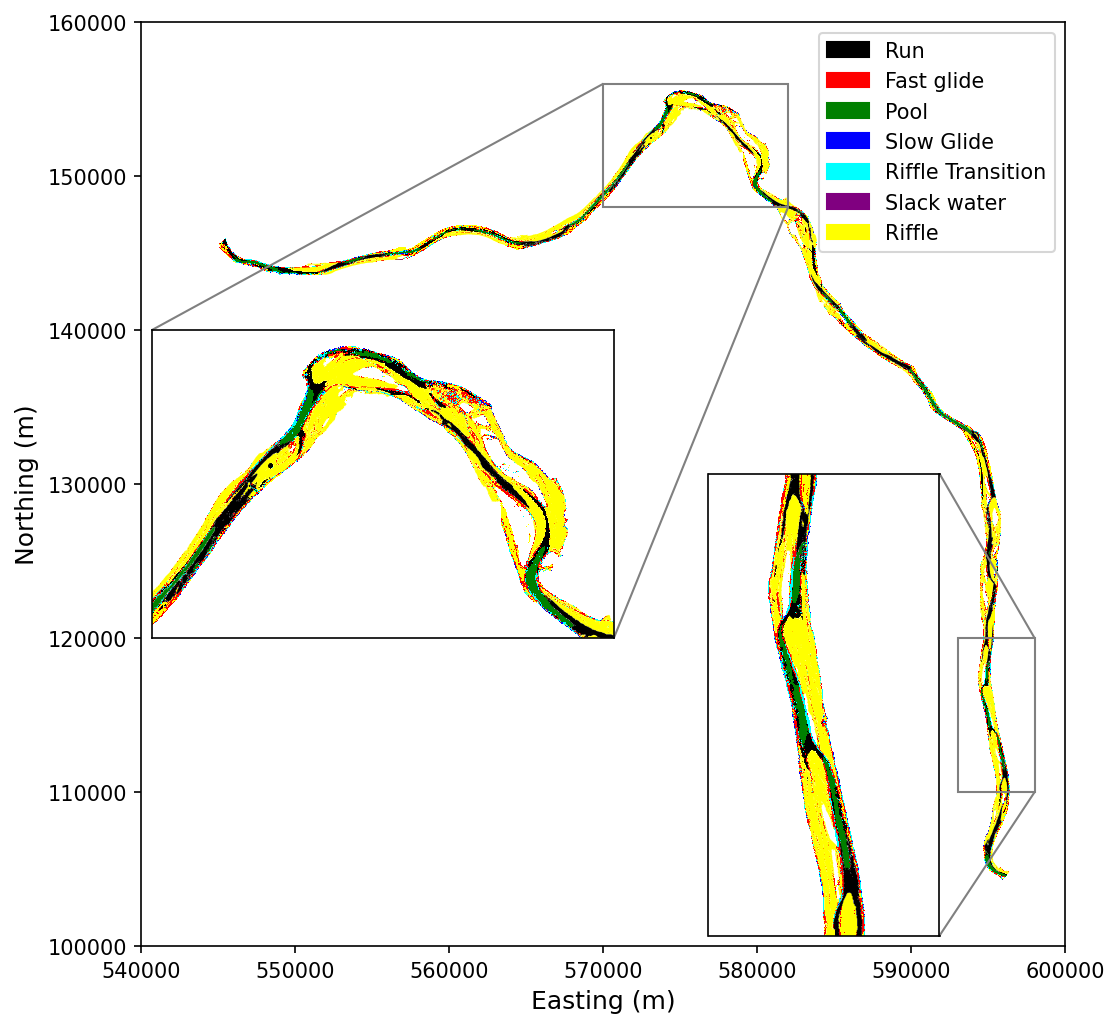

In [194]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
# geom_shape = gpd.read_file(fname_GU_shp).to_crs('ESRI:102349')

# texts    = ["Fast glide", "Slow glide", "Pool", "Deadwater", "Transition", "Slack water", "Riffle"]
texts    = ["Run", "Fast glide", "Pool", "Slow Glide", "Riffle Transition", "Slack water", "Riffle"]
# cmap     = plt.get_cmap('Set1', len(texts))
# col_list = [cmap(i) for i in range(len(texts))]
col_list = ['black', 'red', 'green', 'blue', 'cyan', 'purple', 'yellow']

# colors   = [col_list[i] for i in geom_shape['grid_code'].values - 1]
colors = [col_list[i-1] for i in geom_shape['grid_code'].values]  # use i-1 since code 8 is removed

geom_shape.plot(facecolor=colors, edgecolor='none', ax=ax, alpha=1)


############ add insert plots ###############
# inset 1: upper reach (570-582 km E, 148-156 km N)
axins = inset_axes(
    ax,
    width="50%",     # width relative to parent
    height="50%",    # height relative to parent
    loc="center left",
    borderpad=0.5
)
geom_shape.plot(facecolor=colors, edgecolor='none', ax=axins, alpha=1)
axins.set_xlim([570000, 582000])
axins.set_ylim([148000, 156000])
axins.set_aspect('equal', adjustable='box')
axins.set_xticks([])
axins.set_yticks([])
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5")

###### add another insert #########
axins2 = inset_axes(
    ax,
    width="50%",     # width relative to parent
    height="50%",    # height relative to parent
    loc="lower right",
    # bbox_to_anchor=(0.5, 0.05, 1, 1),
    # bbox_transform=ax.transAxes,
    borderpad=0.5
)
geom_shape.plot(facecolor=colors, edgecolor='none', ax=axins2, alpha=1)
axins2.set_xlim([593000, 598000])
axins2.set_ylim([110000, 120000])
axins2.set_aspect('equal', adjustable='box')
axins2.set_xticks([])
axins2.set_yticks([])
mark_inset(ax, axins2, loc1=1, loc2=4, fc="none", ec="0.5")

ax.set_xlim([540000, 600000])
ax.set_ylim([100000, 160000])
ax.set_aspect("equal")
ax.set_xlabel("Easting (m)", fontsize=12)
ax.set_ylabel("Northing (m)", fontsize=12)

patches = [mpatches.Patch(color=col_list[i], label=texts[i]) for i in range(len(texts))]
ax.legend(handles=patches, bbox_to_anchor=(1, 1), loc='upper right', ncol=1)

In [195]:
fig.savefig(figure_dir + "HU_map_new.jpg", dpi=300)
plt.close(fig)

## Assign HU to river cells (area-weighted spatial overlay)

In [51]:
polys = []
for cell_id in river_cell_ids:
    cell_vertices = all_cell[cell_id, 1:4]
    verts = all_vertices_coord[np.sort(cell_vertices - 1), :]
    polys.append(Polygon(verts[:, :2]))  # XY only

river_gdf = gpd.GeoDataFrame({'cell_id': river_cell_ids}, geometry=polys, crs='ESRI:102349')
# river_gdf.to_file(result_dir + 'river_cell_top_faces.shp')

This may take a while to complete...

In [ ]:
# Area-weighted overlay: assign the GU class that covers the largest fraction of each cell
overlay = gpd.overlay(river_gdf, geom_shape[['grid_code', 'geometry']], how='intersection')
overlay['area'] = overlay.geometry.area
idx = overlay.groupby('cell_id')['area'].idxmax()
best = overlay.loc[idx, ['cell_id', 'grid_code']].set_index('cell_id')
cell_df['HU_id'] = best.reindex(river_cell_ids)['grid_code']

In [58]:
HU_name_list = {1: 'Run', 2: 'Fast glide', 3: 'Pool', 4: 'Slow Glide',
                5: 'Riffle Transition', 6: 'Slack Water', 7: 'Riffle'}
cell_df['HU_name'] = [HU_name_list[i] for i in cell_df.HU_id]

# cell_df.to_pickle(result_dir + 'river_cell_HU.p')

In [60]:
cell_df.to_parquet(result_dir + f'cell_df_temp_perm_HU_2017-2019_layer{ilayer}.parquet')

In [61]:
n_nan = cell_df['HU_id'].isna().sum()
print(f"NaN count: {n_nan} ({n_nan/len(cell_df)*100:.1f}%)")

if n_nan > 0:
    print(cell_df[cell_df['HU_id'].isna()][['x', 'y']])
    

NaN count: 0 (0.0%)


In [62]:
# remove HU_id = NaN cells since they do not have a HU id; those are the cells that are likely on the islands or outside of the riverbed geometry
cell_df = cell_df[cell_df['HU_id'].notna()].copy()
print(f"Remaining cells: {len(cell_df)}")

Remaining cells: 18844


**add geomorphic unit name to river cells**

Note: **fast glide** and **slow glide** are combined into **glide**

In [63]:
hu_counts = cell_df['HU_name'].value_counts()
hu_pct = (hu_counts / len(cell_df) * 100).round(1)
print(pd.DataFrame({'count': hu_counts, 'pct': hu_pct}))

                   count   pct
Riffle             10206  54.2
Run                 3917  20.8
Fast glide          2312  12.3
Pool                1614   8.6
Riffle Transition    694   3.7
Slow Glide           101   0.5


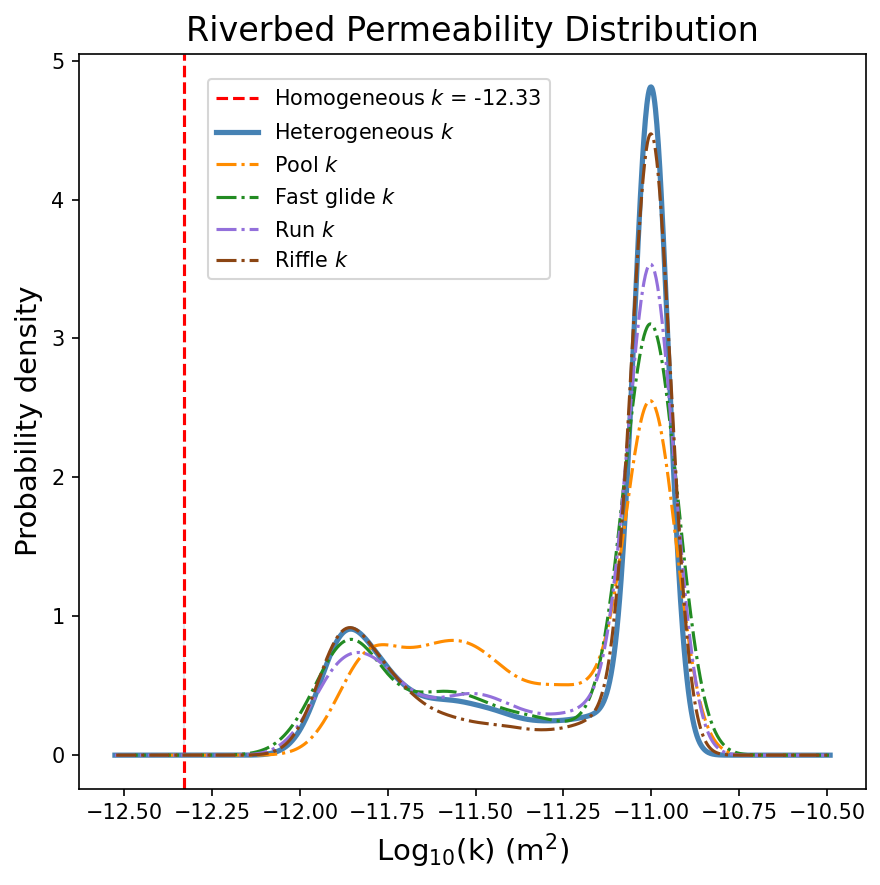

In [64]:
homo_perm_log10 = -12.33
perm_log10 = np.log10(cell_df['perm_value'])

hu_types = {
    'pool':       'darkorange',
    'fast glide': 'forestgreen',
    'run':        'mediumpurple',
    'riffle':     'saddlebrown',
}

fig, ax_kde = plt.subplots(figsize=(6, 6))

# --- Homogeneous perm reference line ---
ax_kde.axvline(homo_perm_log10, color='red', linestyle='--', linewidth=1.5,
               label=f'Homogeneous $k$ = {homo_perm_log10}')
# --- Overall heterogeneous perm KDE (thicker line, light fill) ---
pd.Series(perm_log10).plot.density(ax=ax_kde, color='steelblue', linewidth=2.5, label='Heterogeneous $k$')
x_line, y_line = ax_kde.lines[0].get_xdata(), ax_kde.lines[0].get_ydata()
ax_kde.fill_between(x_line, y_line, alpha=0.15, color='steelblue')  # reduced alpha

# --- Per-HU KDE plots (lines only, no fill) ---
for hu_name, color in hu_types.items():
    mask = cell_df['HU_name'].str.lower() == hu_name.lower()
    hu_perm = np.log10(cell_df.loc[mask, 'perm_value'])

    if mask.sum() < 2:
        print(f"Skipping '{hu_name}': insufficient data ({mask.sum()} points)")
        continue

    hu_perm.plot.density(ax=ax_kde, color=color, linewidth=1.5,
                         linestyle='-.',
                         label=hu_name.capitalize()+' $k$')
    # No fill_between for HU lines — cleaner look



ax_kde.set_xlabel(r"Log$_{10}$(k) (m$^2$)", fontsize=14)
ax_kde.set_ylabel("Probability density", fontsize=14)
ax_kde.set_title("Riverbed Permeability Distribution", fontsize=16)
# ax_kde.legend(loc='upper center')
ax_kde.legend(loc='upper left', bbox_to_anchor=(0.15, 0.98))
plt.tight_layout()
plt.show()

In [42]:
fig.savefig(figure_dir + "perm_kde.jpg", dpi=300)
plt.close(fig)

**Only select the dominant geomorphic units: Run, Pool, Fast Glide, and Riffle**
(accounts for ~95.8% of entire reach)

In [66]:
cell_df_sub = cell_df[cell_df['HU_name'].isin(['Pool', 'Riffle', 'Fast glide', 'Run'])]

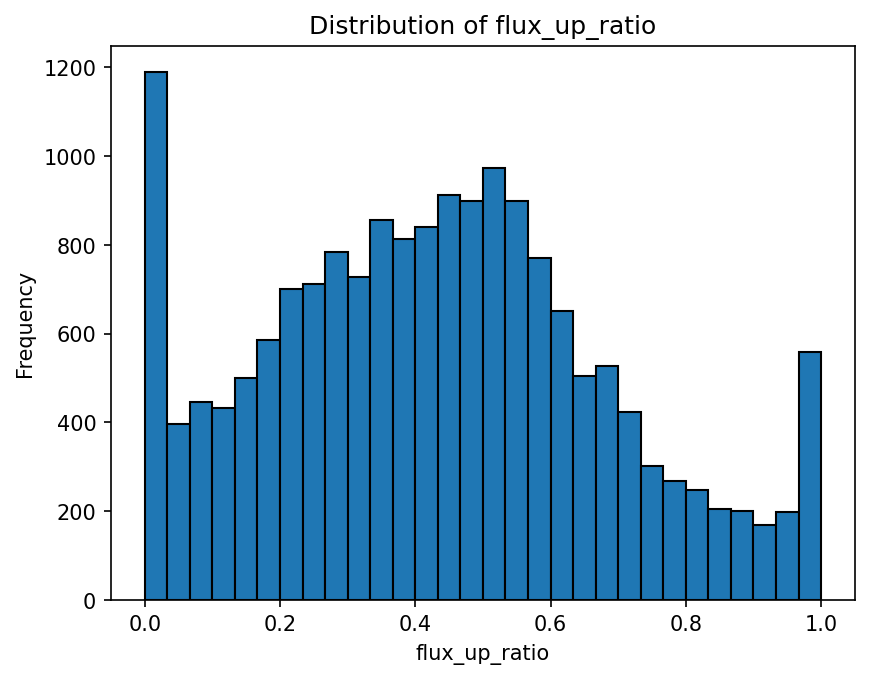

In [24]:
cell_df_sub['flux_up_ratio'].plot(kind='hist', bins=30, edgecolor='black')
plt.xlabel('flux_up_ratio')
plt.title('Distribution of flux_up_ratio')
plt.show()

# River morphology impact

In [67]:
ratio_threshold = 0.5
df = cell_df_sub.copy()
df['flow_idx'] = ['Downwelling dominated' if i < ratio_threshold else 'Upwelling dominated'
                  for i in df.flux_up_ratio]

for season in ['winter', 'spring', 'summer', 'fall']:
    df[f'flow_idx_{season}'] = [
        'Downwelling dominated' if i < ratio_threshold else 'Upwelling dominated'
        for i in df[f'gaining_ratio_{season}']
    ]

df['placeholder'] = 'placeholder'

In [68]:
arr = []
for iseason in ['winter', 'spring', 'summer', 'fall']:
    d1 = np.array(np.unique(df[f'flow_idx_{iseason}'].values, return_counts=True)).transpose()
    d2 = np.array([iseason] * 2).reshape(2, 1)
    d3 = np.concatenate((d1, d2), axis=1)
    arr.append(d3)
df_count = pd.DataFrame(np.vstack(arr), columns=['hue', 'Counts', 'season'])
df_count

,hue,Counts,season
0,Downwelling dominated,10641,winter
1,Upwelling dominated,7408,winter
2,Downwelling dominated,11179,spring
3,Upwelling dominated,6870,spring
4,Downwelling dominated,7199,summer
5,Upwelling dominated,10850,summer
6,Downwelling dominated,7353,fall
7,Upwelling dominated,10696,fall


In [25]:
# ratio_threshold = 0.75

# def classify_flow(r, thr=ratio_threshold):
#     if r >= thr:
#         return 'Upwelling dominated'
#     if r <= 1 - thr:
#         return 'Downwelling dominated'
#     return 'Mixed'

# df = cell_df_sub.copy()
# df['flow_idx'] = [classify_flow(i) for i in df.flux_up_ratio]

# for season in ['winter', 'spring', 'summer', 'fall']:
#     df[f'flow_idx_{season}'] = [classify_flow(i) for i in df[f'gaining_ratio_{season}']]

# df['placeholder'] = 'placeholder'

In [27]:
# arr = []
# for iseason in ['winter', 'spring', 'summer', 'fall']:
#     d1 = np.array(np.unique(df[f'flow_idx_{iseason}'].values, return_counts=True)).transpose()
#     d2 = np.array([iseason] * len(d1)).reshape(-1, 1)
#     d3 = np.concatenate((d1, d2), axis=1)
#     arr.append(d3)
# df_count = pd.DataFrame(np.vstack(arr), columns=['hue', 'Counts', 'season'])
# df_count

,hue,Counts,season
0,Downwelling dominated,5723,winter
1,Mixed,10650,winter
2,Upwelling dominated,1676,winter
3,Downwelling dominated,6337,spring
4,Mixed,8793,spring
5,Upwelling dominated,2919,spring
6,Downwelling dominated,3358,summer
7,Mixed,10967,summer
8,Upwelling dominated,3724,summer
9,Downwelling dominated,4235,fall


In [69]:
df_idx      = df[['flow_idx_winter', 'flow_idx_spring', 'flow_idx_summer', 'flow_idx_fall']]
unique_list = [len(np.unique(df_idx.iloc[i, :])) for i in np.arange(df_idx.shape[0])]
arr         = np.array(np.unique(unique_list, return_counts=True)).transpose()
arr

print(f'{arr[0, 1] / arr[:, 1].sum() * 100:.1f}% river cells stay the same upwelling or downwelling condition over a year;\n'
      f'{arr[1, 1] / arr[:, 1].sum() * 100:.1f}% river cells change the dominant flow conditions')

46.5% river cells stay the same upwelling or downwelling condition over a year;
53.5% river cells change the dominant flow conditions


## Plot upwelling/downwelling trend over seasons

In [70]:
df_count['Counts'] = df_count['Counts'].astype(int)
df_pivot = df_count.pivot(index='season', columns='hue', values='Counts')
df_pivot = df_pivot.loc[['winter', 'spring', 'summer', 'fall']]
df_ratio = df_pivot.div(df_pivot.sum(axis=1), axis=0)

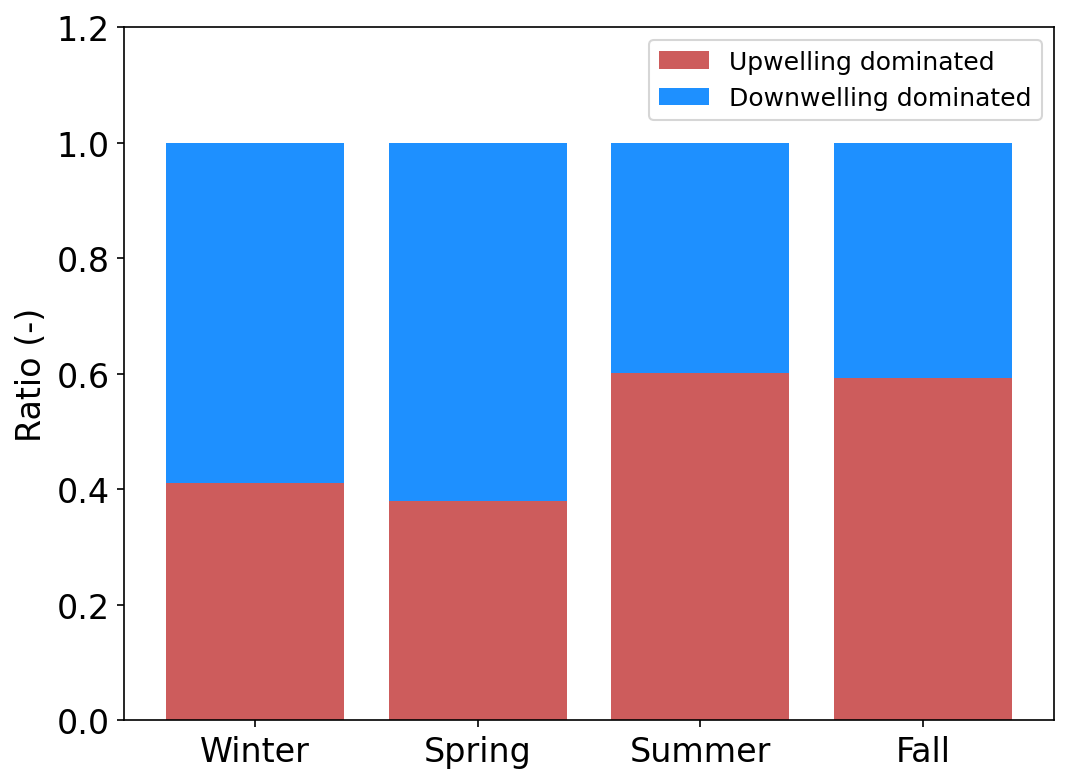

In [71]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.bar(range(4), df_ratio['Upwelling dominated'],   color='indianred',  label='Upwelling dominated')
ax.bar(range(4), df_ratio['Downwelling dominated'], color='dodgerblue', label='Downwelling dominated',
       bottom=df_ratio['Upwelling dominated'])
ax.set_xticks(range(4))
ax.set_xticklabels(['Winter', 'Spring', 'Summer', 'Fall'], fontsize=16)
ax.set_xlabel('')
ax.set_ylabel('Ratio (-)', fontsize=16)
ax.set_ylim([0, 1.2])
ax.tick_params(axis='both', which='major', labelsize=16)
ax.legend(title='', loc='upper right', fontsize=12)

In [72]:
fig.savefig(figure_dir + f"upwelling_ratio_by_season_layer{ilayer}.jpg", dpi=300)
plt.close(fig)

## HU thermal dynamics analysis
Expected pattern: riffle=downwelling, pool=upwelling, glide=intermediate

In [73]:
HU_order   = ['Pool', 'Fast glide', 'Run', 'Riffle']
HU_palette = {
    'Pool':       'green',
    'Fast glide': 'red',
    'Run': 'gray',
    'Riffle':  'yellow',
}

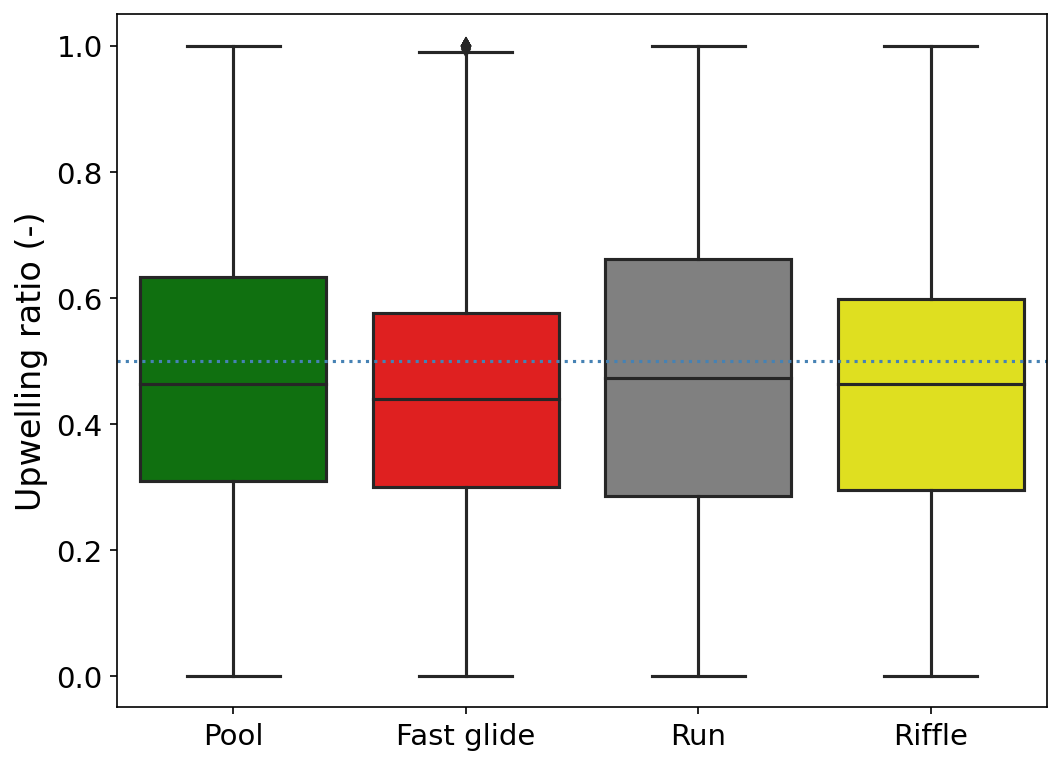

In [74]:
# ### Plot 1: Gaining ratio by HU (confirm basic flow pattern)


fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.boxplot(x='HU_name', y='gaining_ratio', data=df,
            order=HU_order, palette=HU_palette, ax=ax)
ax.axhline(0.5, color='steelblue', linestyle=':', linewidth=1.5)
# ax.text(1.01, 0.5, 'Equal gaining/losing', transform=ax.get_yaxis_transform(),
#         va='center', ha='left', fontsize=12)
ax.set_xlabel('')
ax.set_ylabel('Upwelling ratio (-)', fontsize=16)
ax.set_ylim([-0.05, 1.05])
ax.tick_params(axis='both', which='major', labelsize=14)

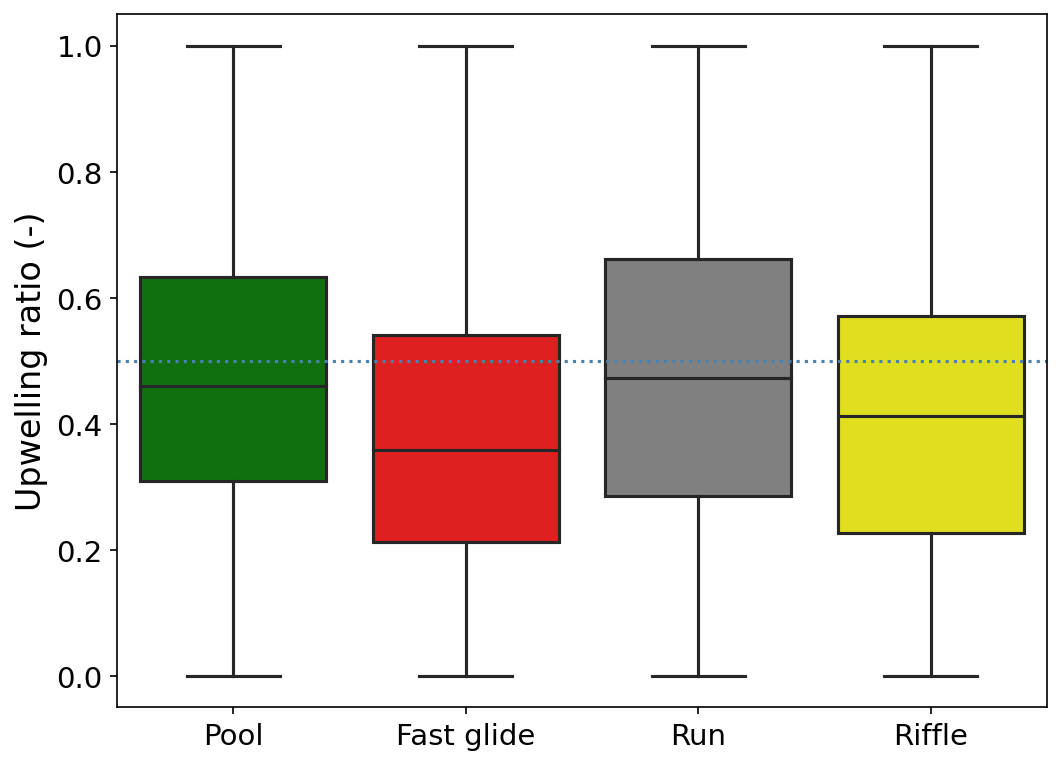

In [75]:
fig.savefig(figure_dir + f"gaining_ratio_by_HU_layer{ilayer}.jpg", dpi=300)
plt.close(fig)

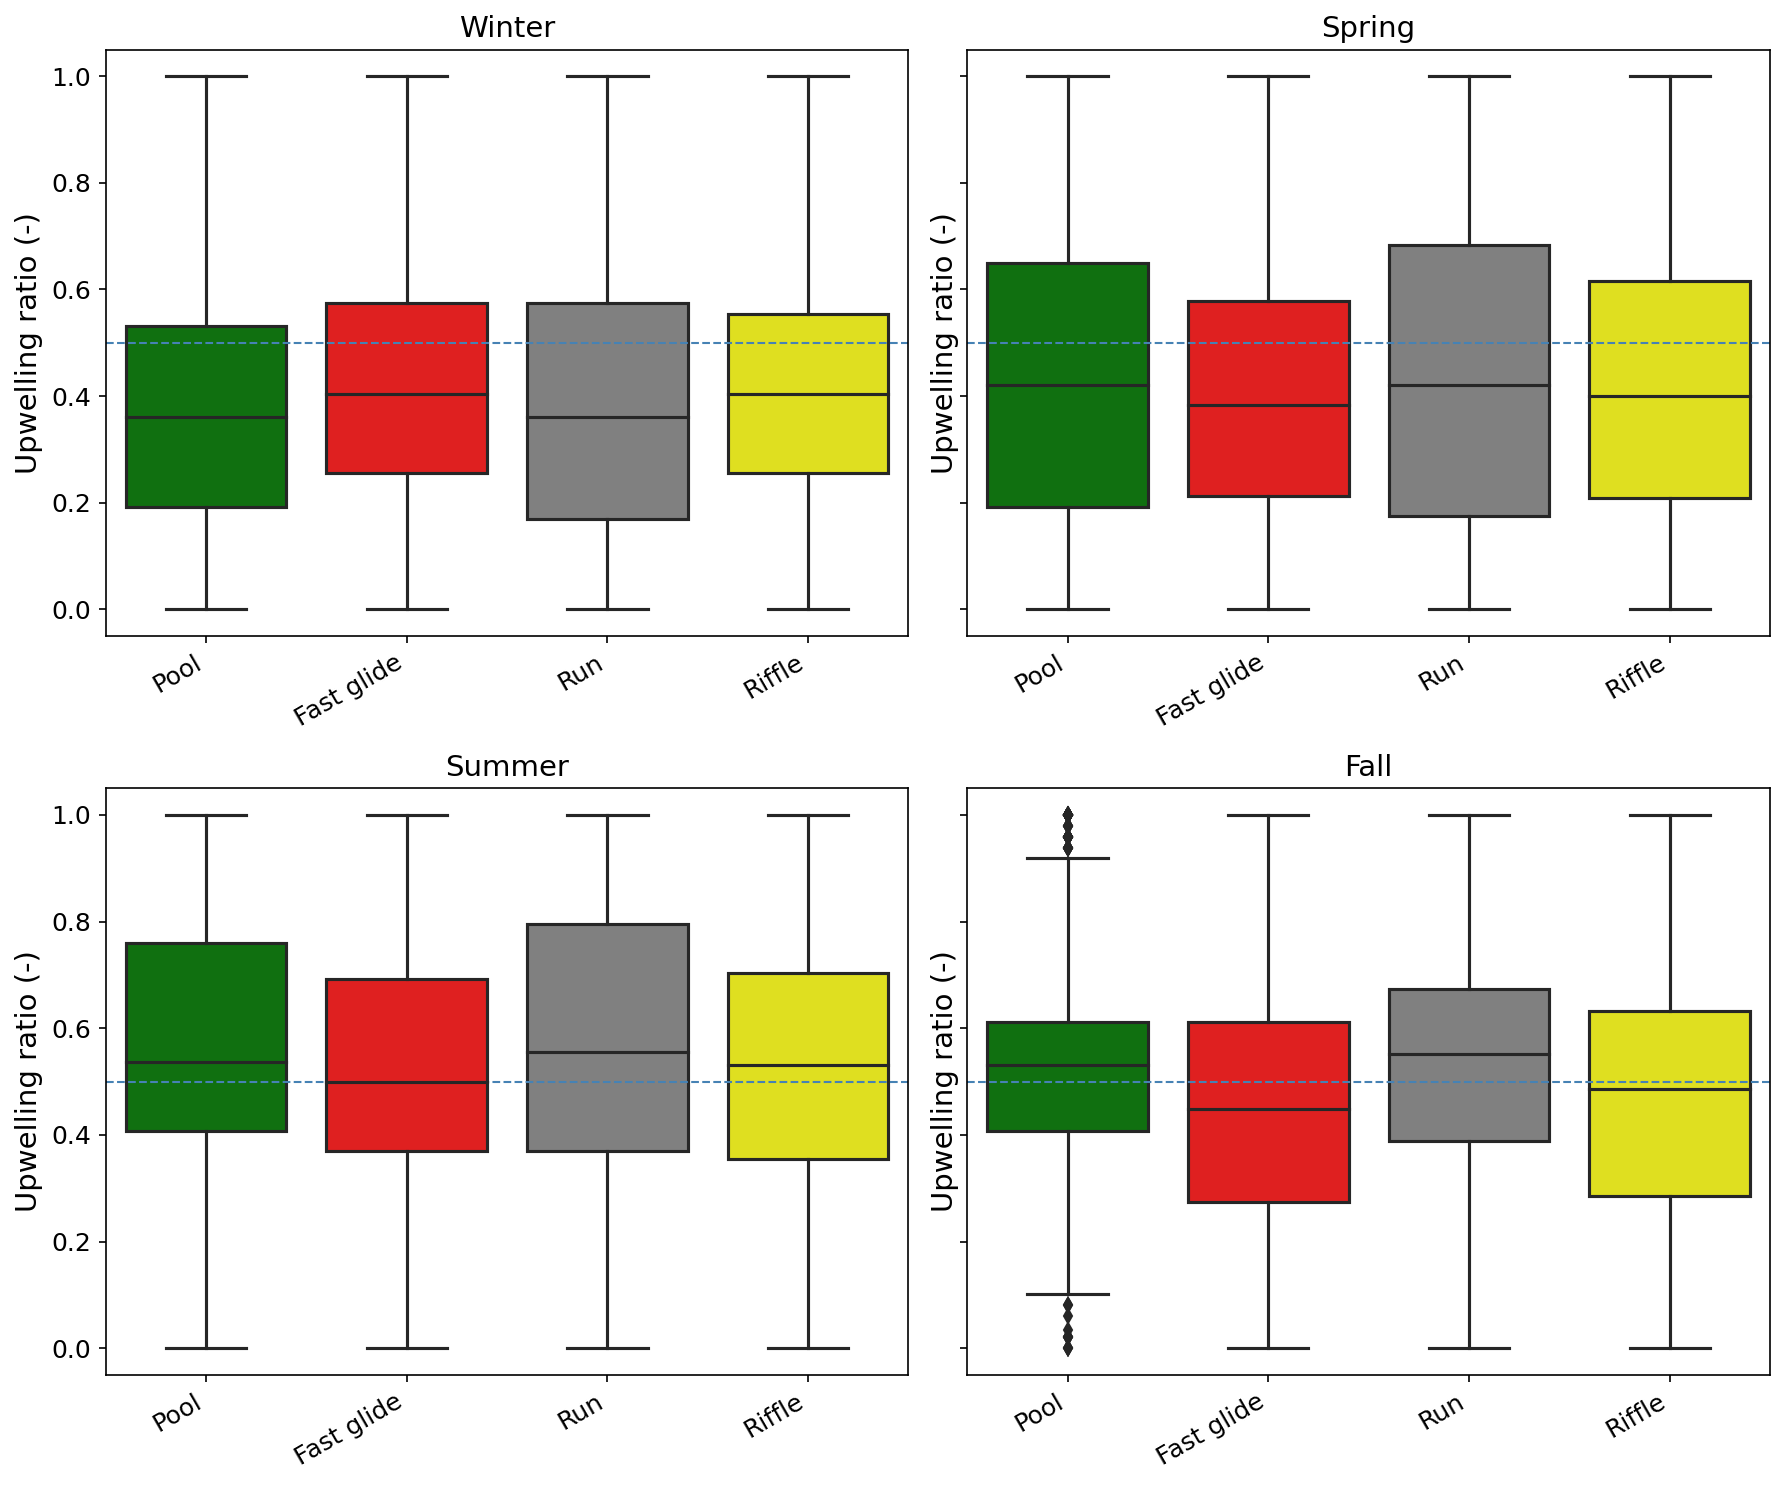

In [76]:
# ### Plot 2: Seasonal gaining ratio by HU (does pattern hold year-round?)


fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True)
for ax, season in zip(axes.flat, ['winter', 'spring', 'summer', 'fall']):
    sns.boxplot(x='HU_name', y=f'gaining_ratio_{season}', data=df,
                order=HU_order, palette=HU_palette, ax=ax)
    ax.axhline(0.5, color='steelblue', linestyle='--', linewidth=1)
    ax.set_title(season.capitalize(), fontsize=14)
    ax.set_xlabel('')
    ax.set_ylim([-0.05, 1.05])
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.set_ylabel('Upwelling ratio (-)', fontsize=14)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
fig.tight_layout()

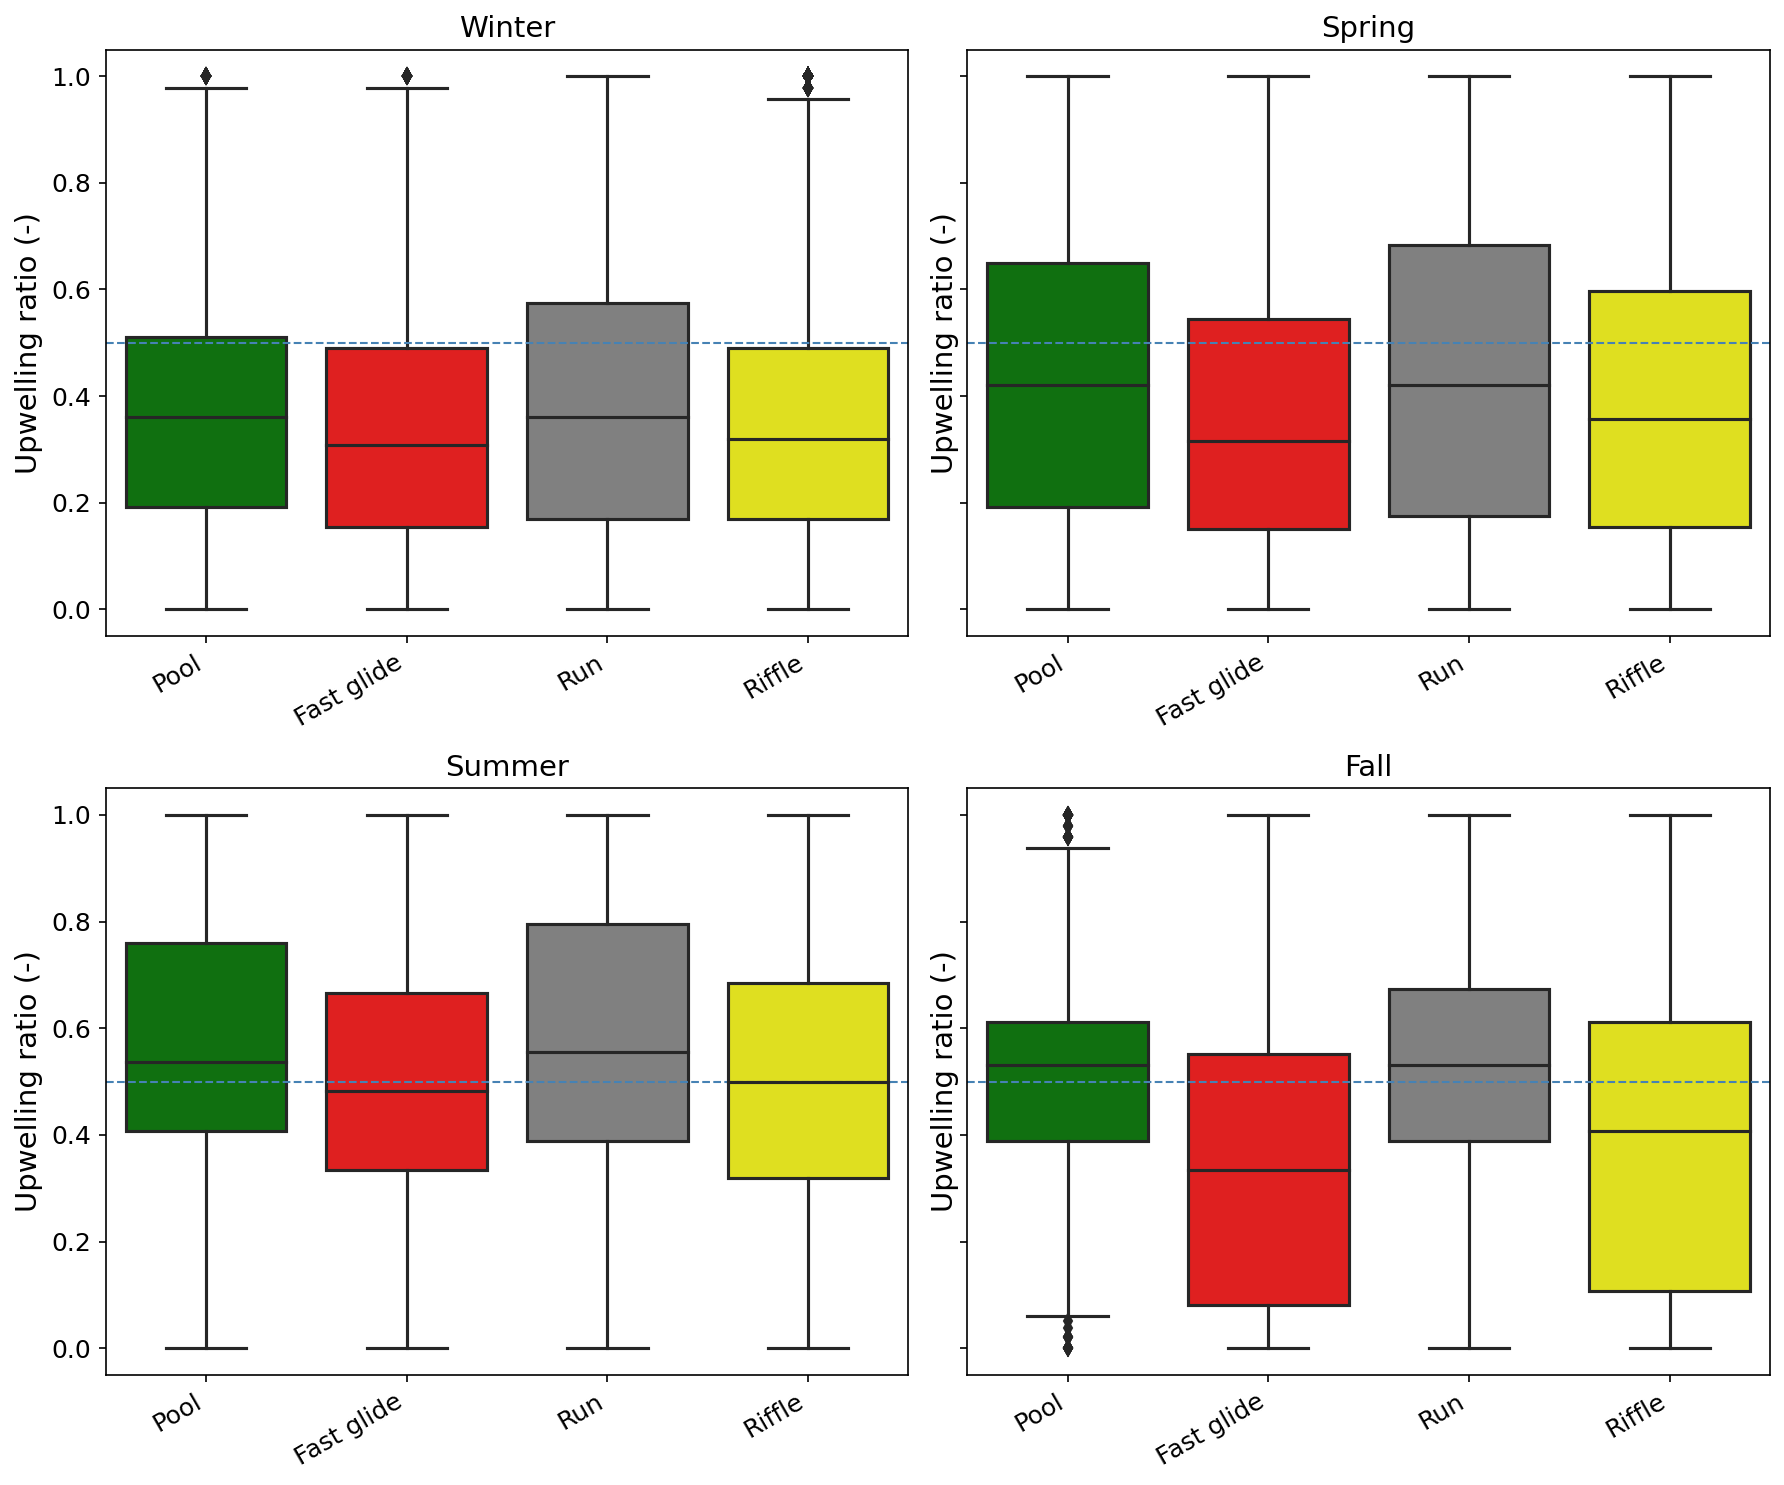

In [77]:
fig.savefig(figure_dir + f"gaining_ratio_seasonal_by_HU_layer{ilayer}.jpg", dpi=300)
plt.close(fig)

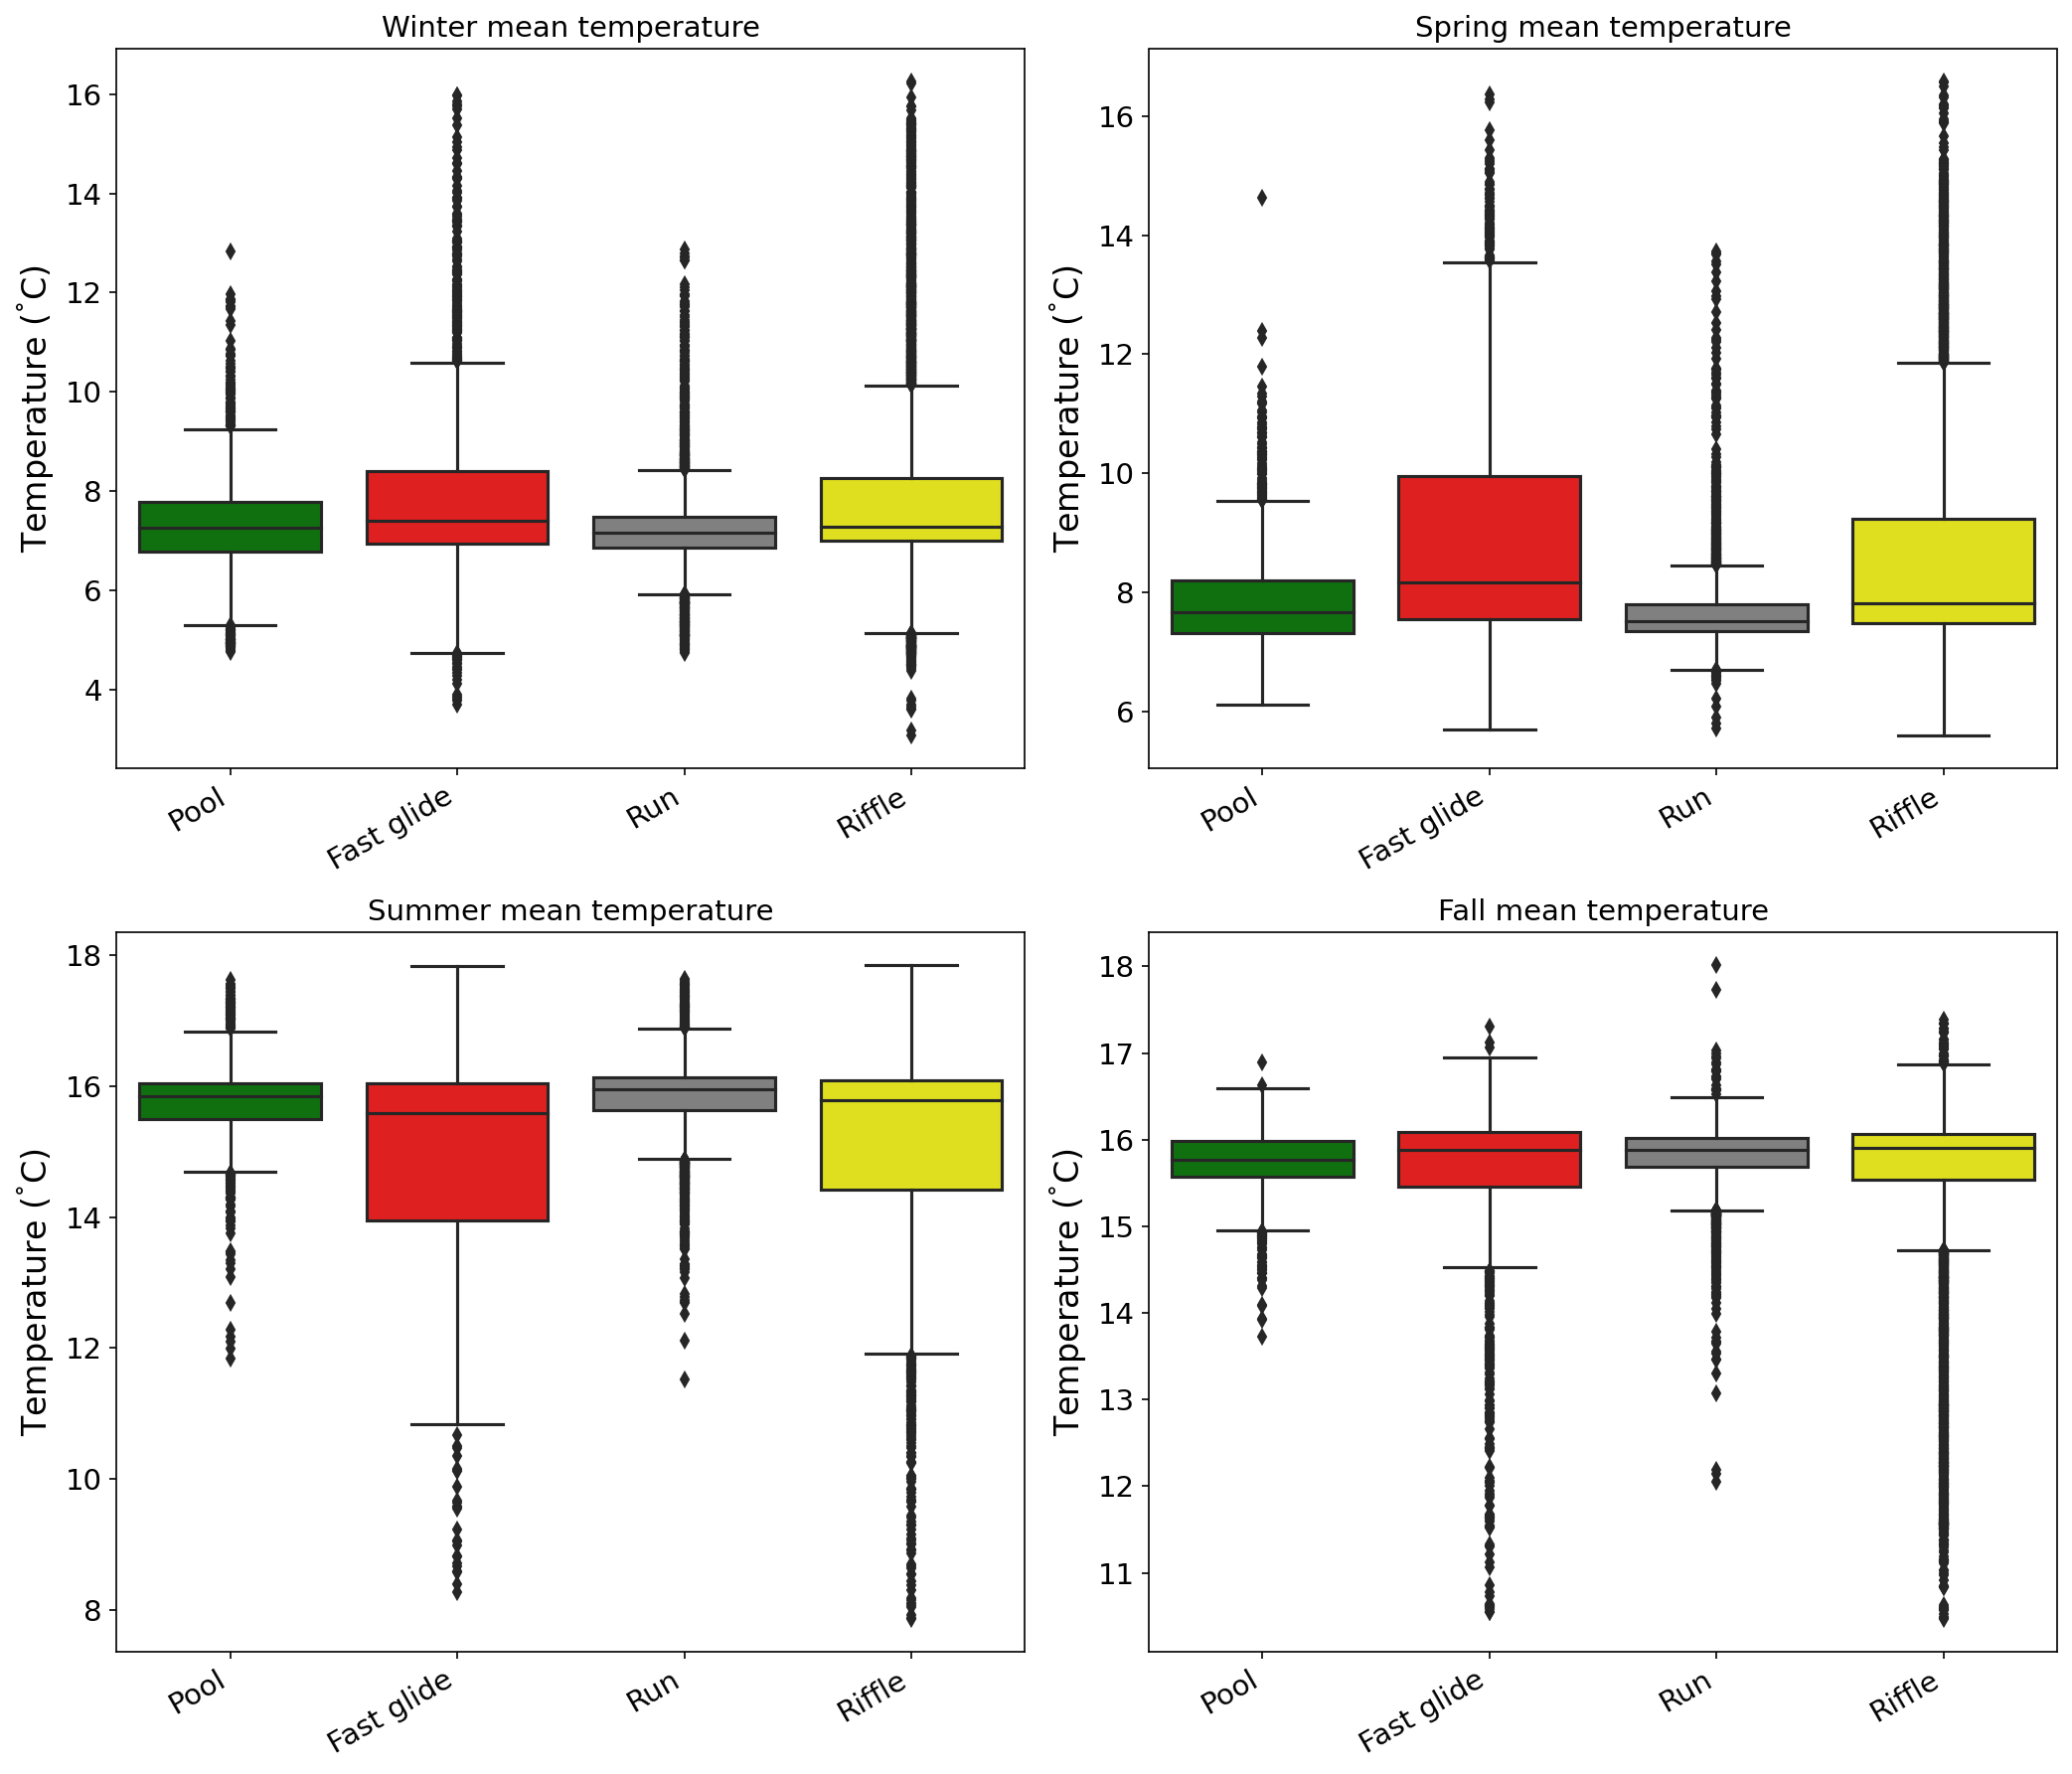

In [78]:
# ### Plot 3: Summer and winter mean temperature by HU (upwelling = buffered)

fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharey=False)
for ax, col, title in zip(axes.flat,
                           ['temp_mean_winter', 'temp_mean_spring',
                            'temp_mean_summer', 'temp_mean_fall'],
                           ['Winter mean temperature', 'Spring mean temperature',
                            'Summer mean temperature', 'Fall mean temperature']):
    sns.boxplot(x='HU_name', y=col, data=df,
                order=HU_order, palette=HU_palette, ax=ax)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('')
    ax.set_ylabel('Temperature ($^\\degree$C)', fontsize=16)
    ax.tick_params(axis='both', which='major', labelsize=14)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
fig.tight_layout()

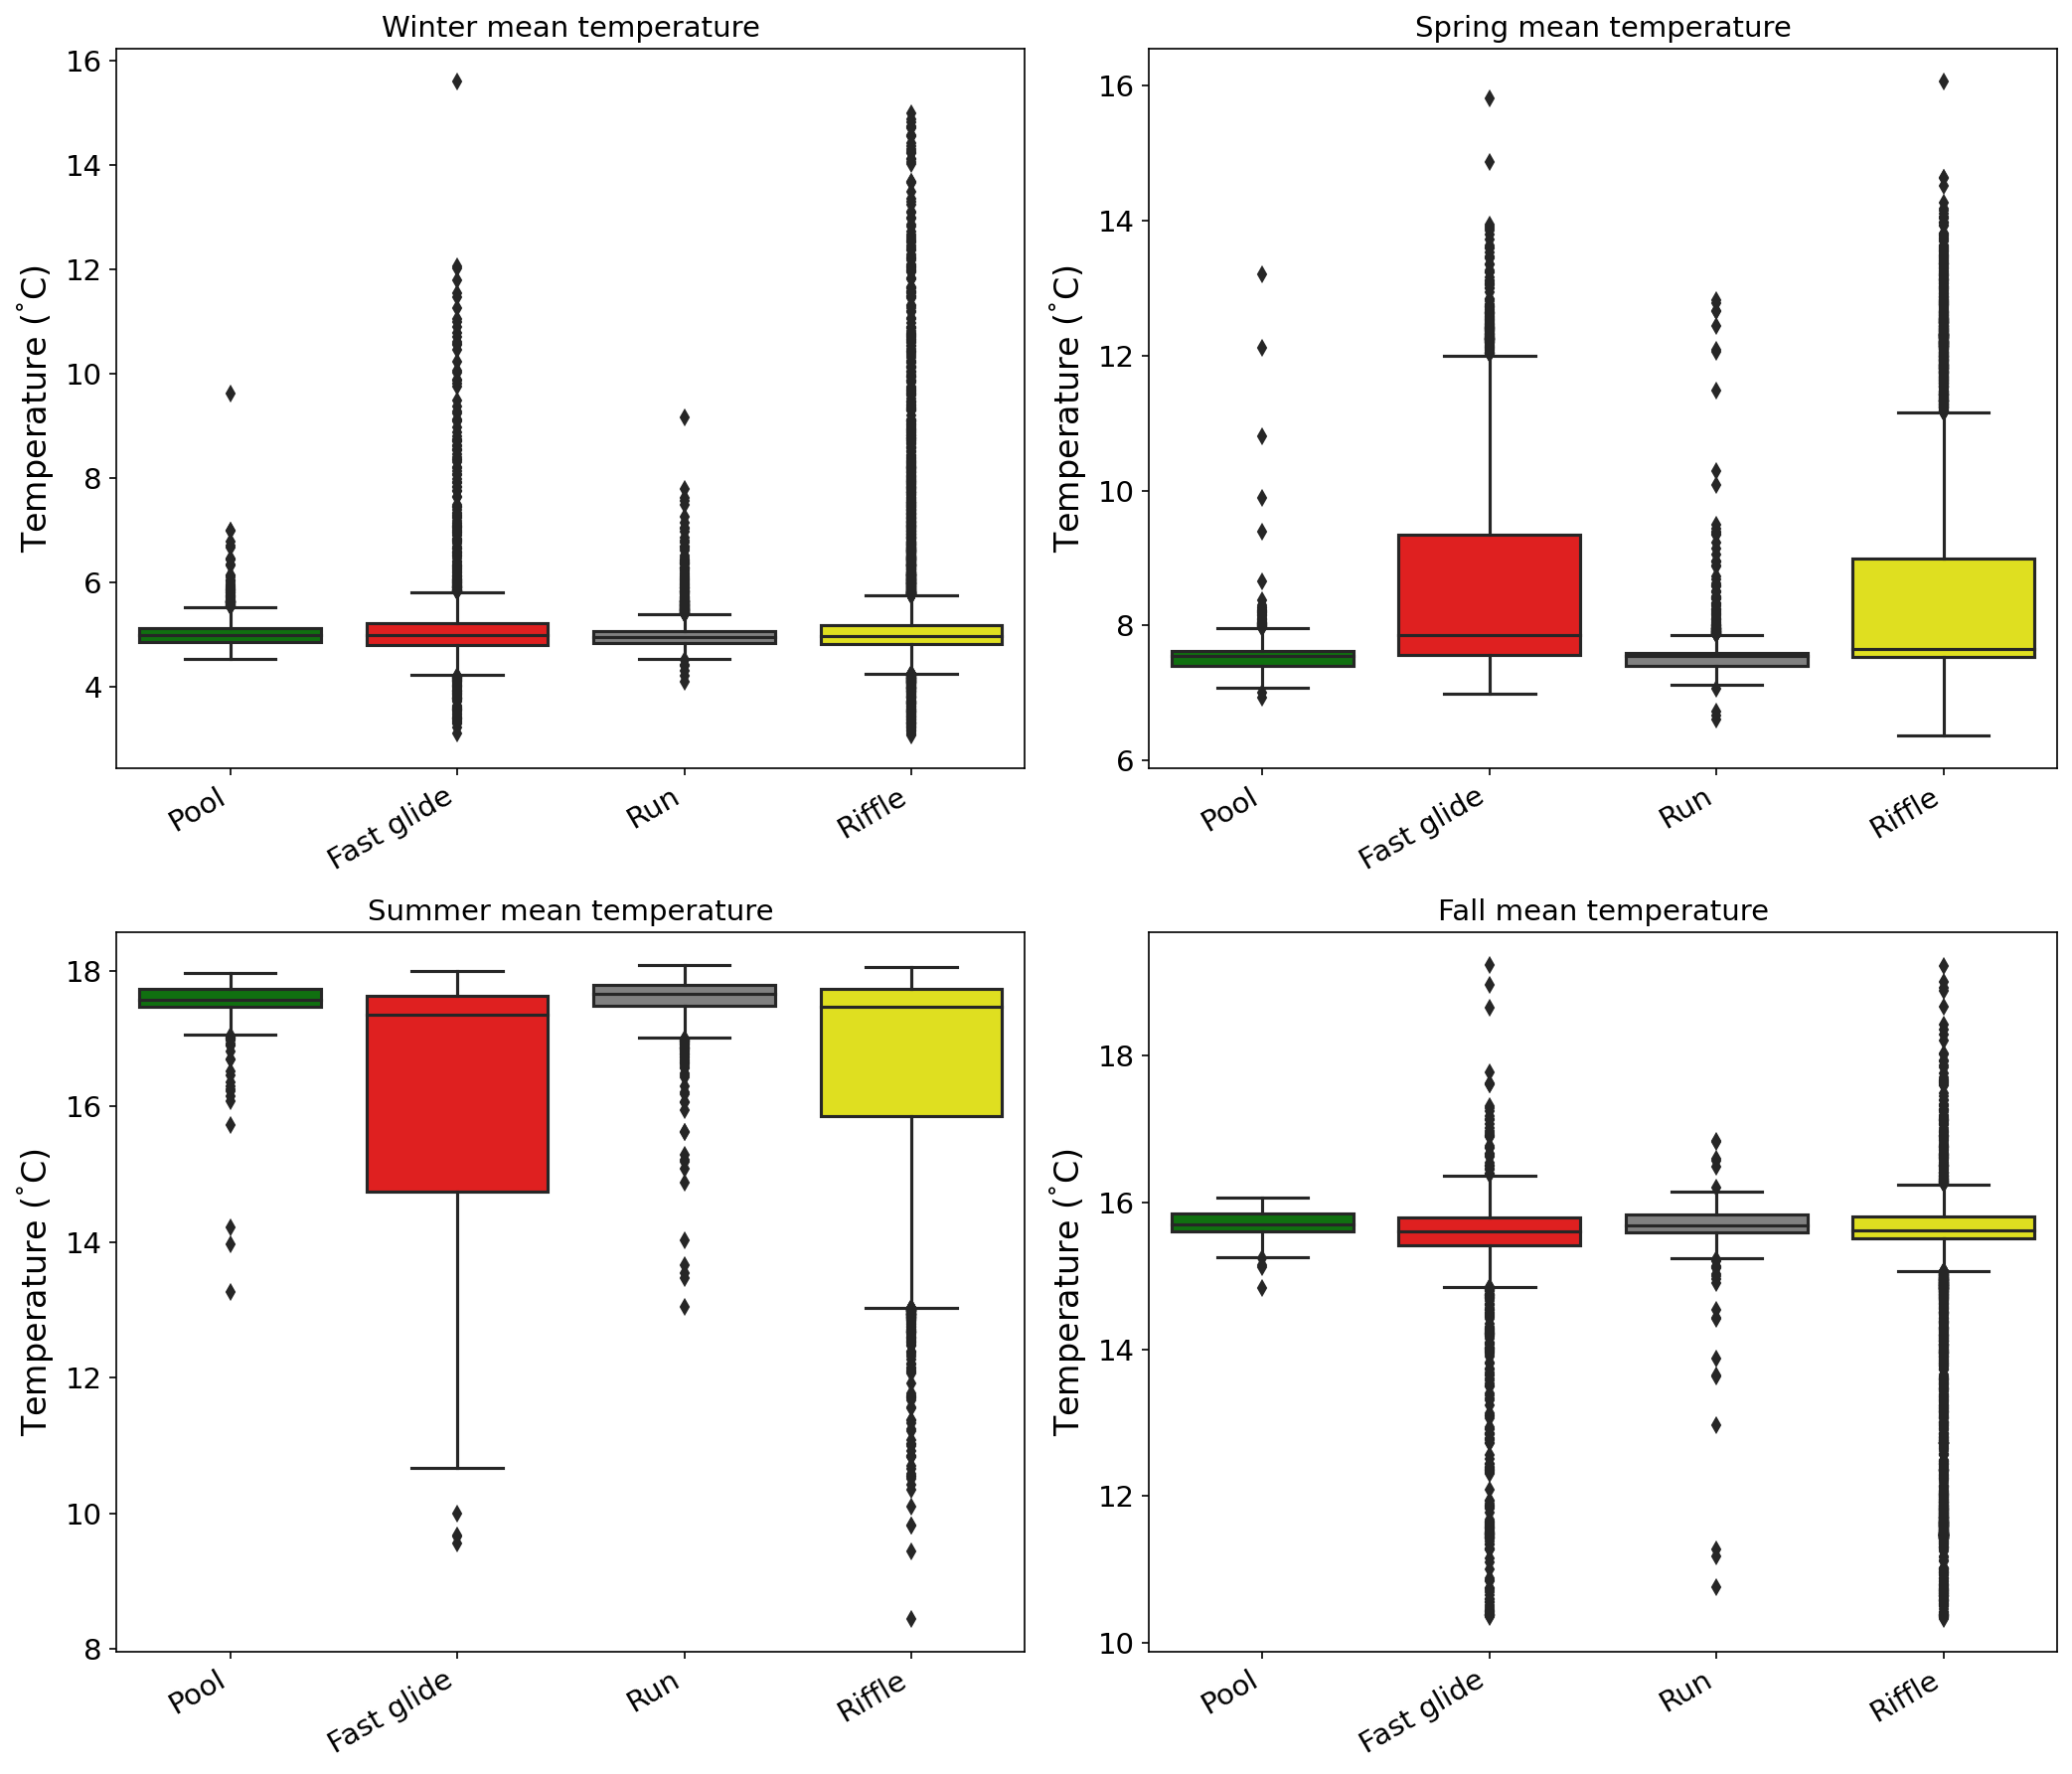

In [79]:
fig.savefig(figure_dir + f"mean_temp_season_by_HU_layer{ilayer}.jpg", dpi=300)
plt.close(fig)

[Text(0, 0, 'Pool'),
 Text(1, 0, 'Fast glide'),
 Text(2, 0, 'Run'),
 Text(3, 0, 'Riffle')]

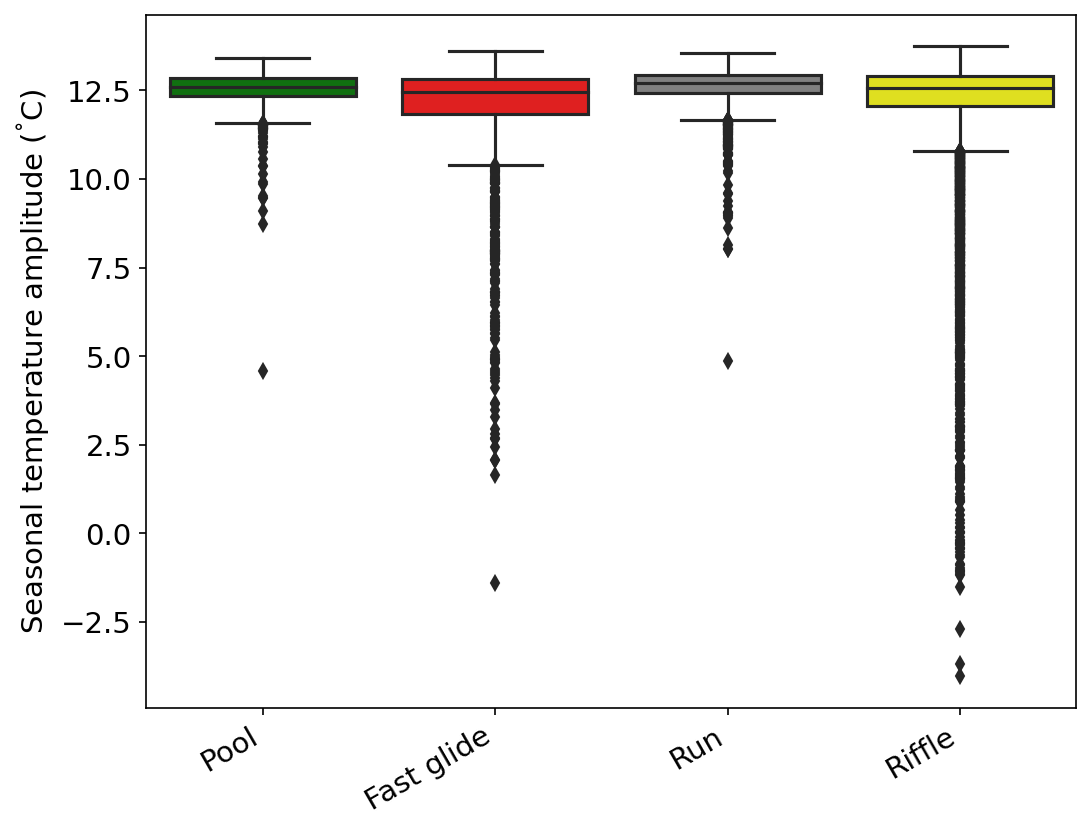

In [213]:
# ### Plot 4: Seasonal temperature amplitude by HU (upwelling dampens swings) Summer temp - winter Temp


fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.boxplot(x='HU_name', y='temp_summer_winter_amp', data=df,
            order=HU_order, palette=HU_palette, ax=ax)
ax.set_xlabel('')
ax.set_ylabel('Seasonal temperature amplitude ($^\\degree$C)', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')

# fig.savefig(figure_dir + "temp_seasonal_amp_by_HU.jpg", dpi=300)
# plt.close(fig)

[Text(0, 0, 'Pool'),
 Text(1, 0, 'Fast glide'),
 Text(2, 0, 'Run'),
 Text(3, 0, 'Riffle')]

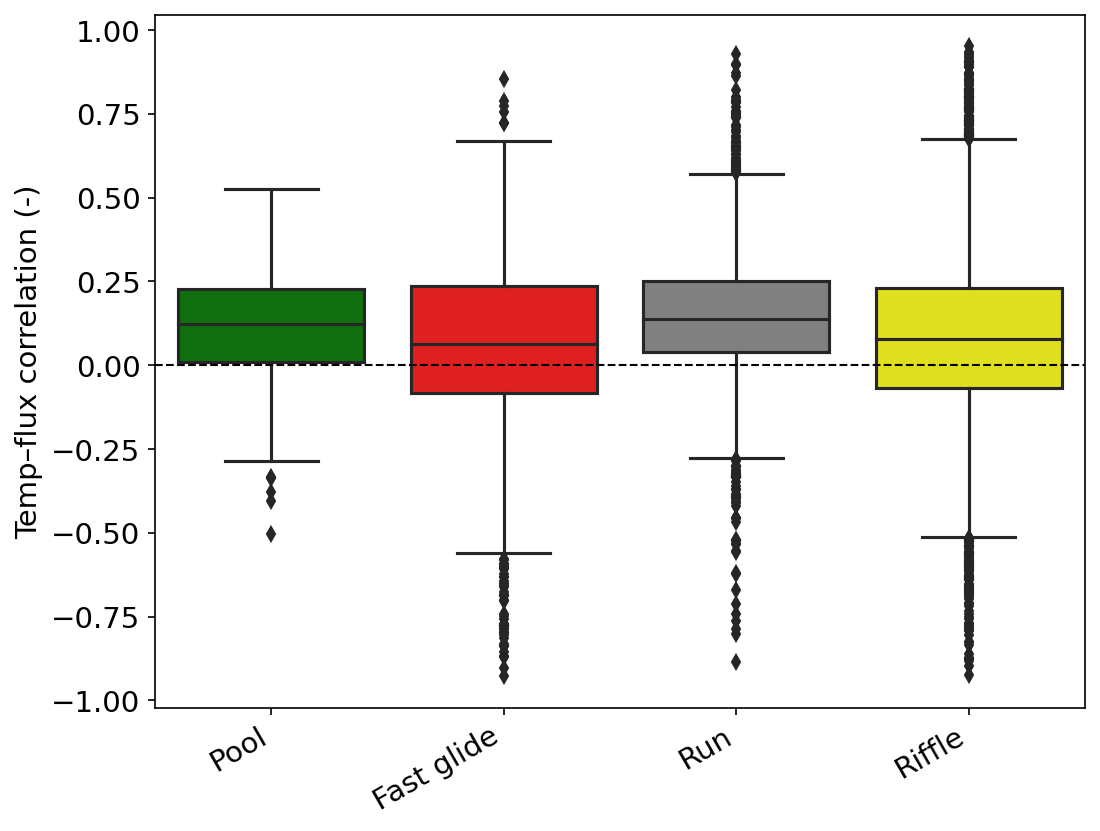

In [214]:
# ### Plot 5: Temp-flux correlation by HU (mechanistic link)
# Positive = upwelling brings warmer groundwater; negative = downwelling pushes cool river water down


fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.boxplot(x='HU_name', y='temp_flux_corr', data=df,
            order=HU_order, palette=HU_palette, ax=ax)
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.set_xlabel('')
ax.set_ylabel('Temp–flux correlation (-)', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')

# fig.savefig(figure_dir + "temp_flux_corr_by_HU.jpg", dpi=300)
# plt.close(fig)

# Riverbed perm impact

In [80]:
df['log_perm'] = np.log10(df['perm_value'])

In [81]:
# Hybrid perm bins based on bimodal distribution structure:
# low-perm mode (~-12.0), trough, high-perm mode (~-11.0)
perm_order   = ['Low\n(<-11.5)', 'Med\n(-11.5 to -11.2)', 'High\n(-11.2 to -11)']
perm_palette = {'Low\n(<-11.5)': 'steelblue', 'Med\n(-11.5 to -11.2)': 'goldenrod', 'High\n(-11.2 to -11)': 'tomato'}
df['perm_bin'] = pd.cut(df['log_perm'],
                        bins=[-np.inf, -11.5, -11.2, np.inf],
                        labels=perm_order)
print("Perm bin counts:\n", df['perm_bin'].value_counts().loc[perm_order])

seasons  = ['all', 'winter', 'spring', 'summer', 'fall']
temp_cols = {
    'all':    'temp_mean',
    'winter': 'temp_mean_winter',
    'spring': 'temp_mean_spring',
    'summer': 'temp_mean_summer',
    'fall':   'temp_mean_fall',
}

Perm bin counts:
 Low\n(<-11.5)             5157
Med\n(-11.5 to -11.2)     1466
High\n(-11.2 to -11)     11426
Name: perm_bin, dtype: int64


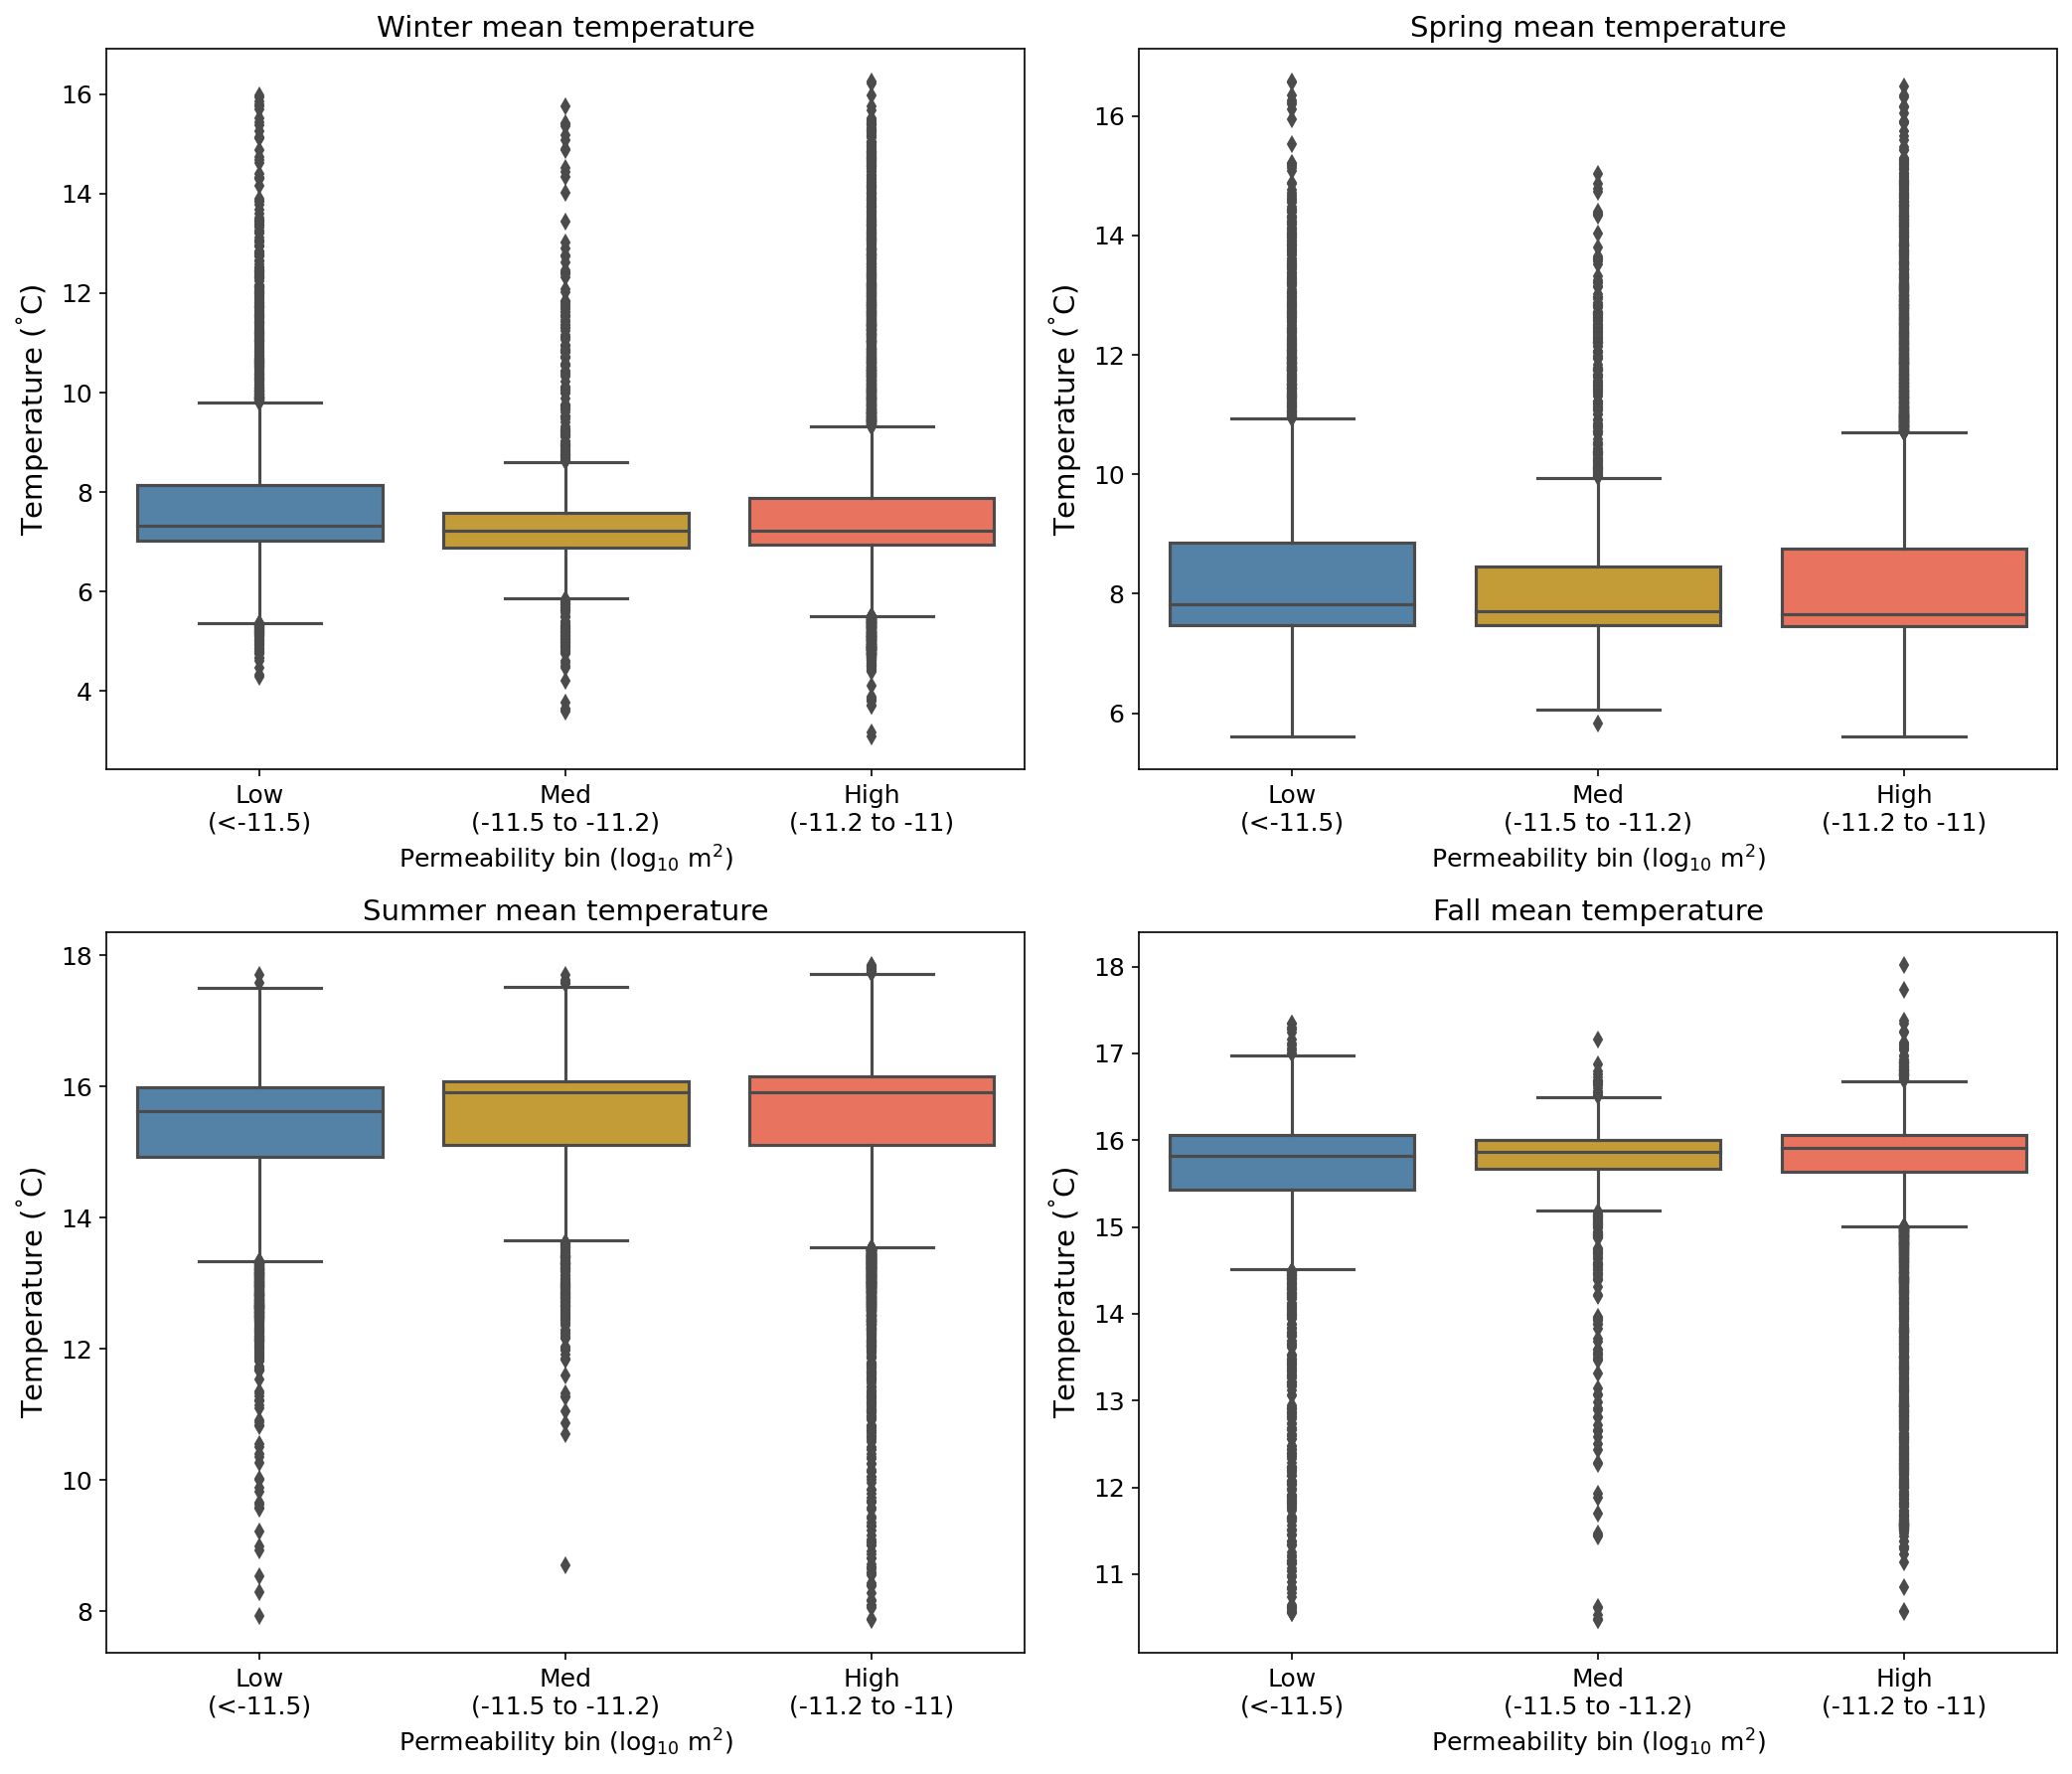

In [82]:
# ### Seasonal mean temperature by permeability bin

fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharey=False)
for ax, col, title in zip(axes.flat,
                           ['temp_mean_winter', 'temp_mean_spring',
                            'temp_mean_summer', 'temp_mean_fall'],
                           ['Winter mean temperature', 'Spring mean temperature',
                            'Summer mean temperature', 'Fall mean temperature']):
    sns.boxplot(x='perm_bin', y=col, data=df,
                order=perm_order, palette=perm_palette, ax=ax)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Permeability bin (log$_{10}$ m$^2$)', fontsize=12)
    ax.set_ylabel('Temperature ($^\\degree$C)', fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=12)
fig.tight_layout()

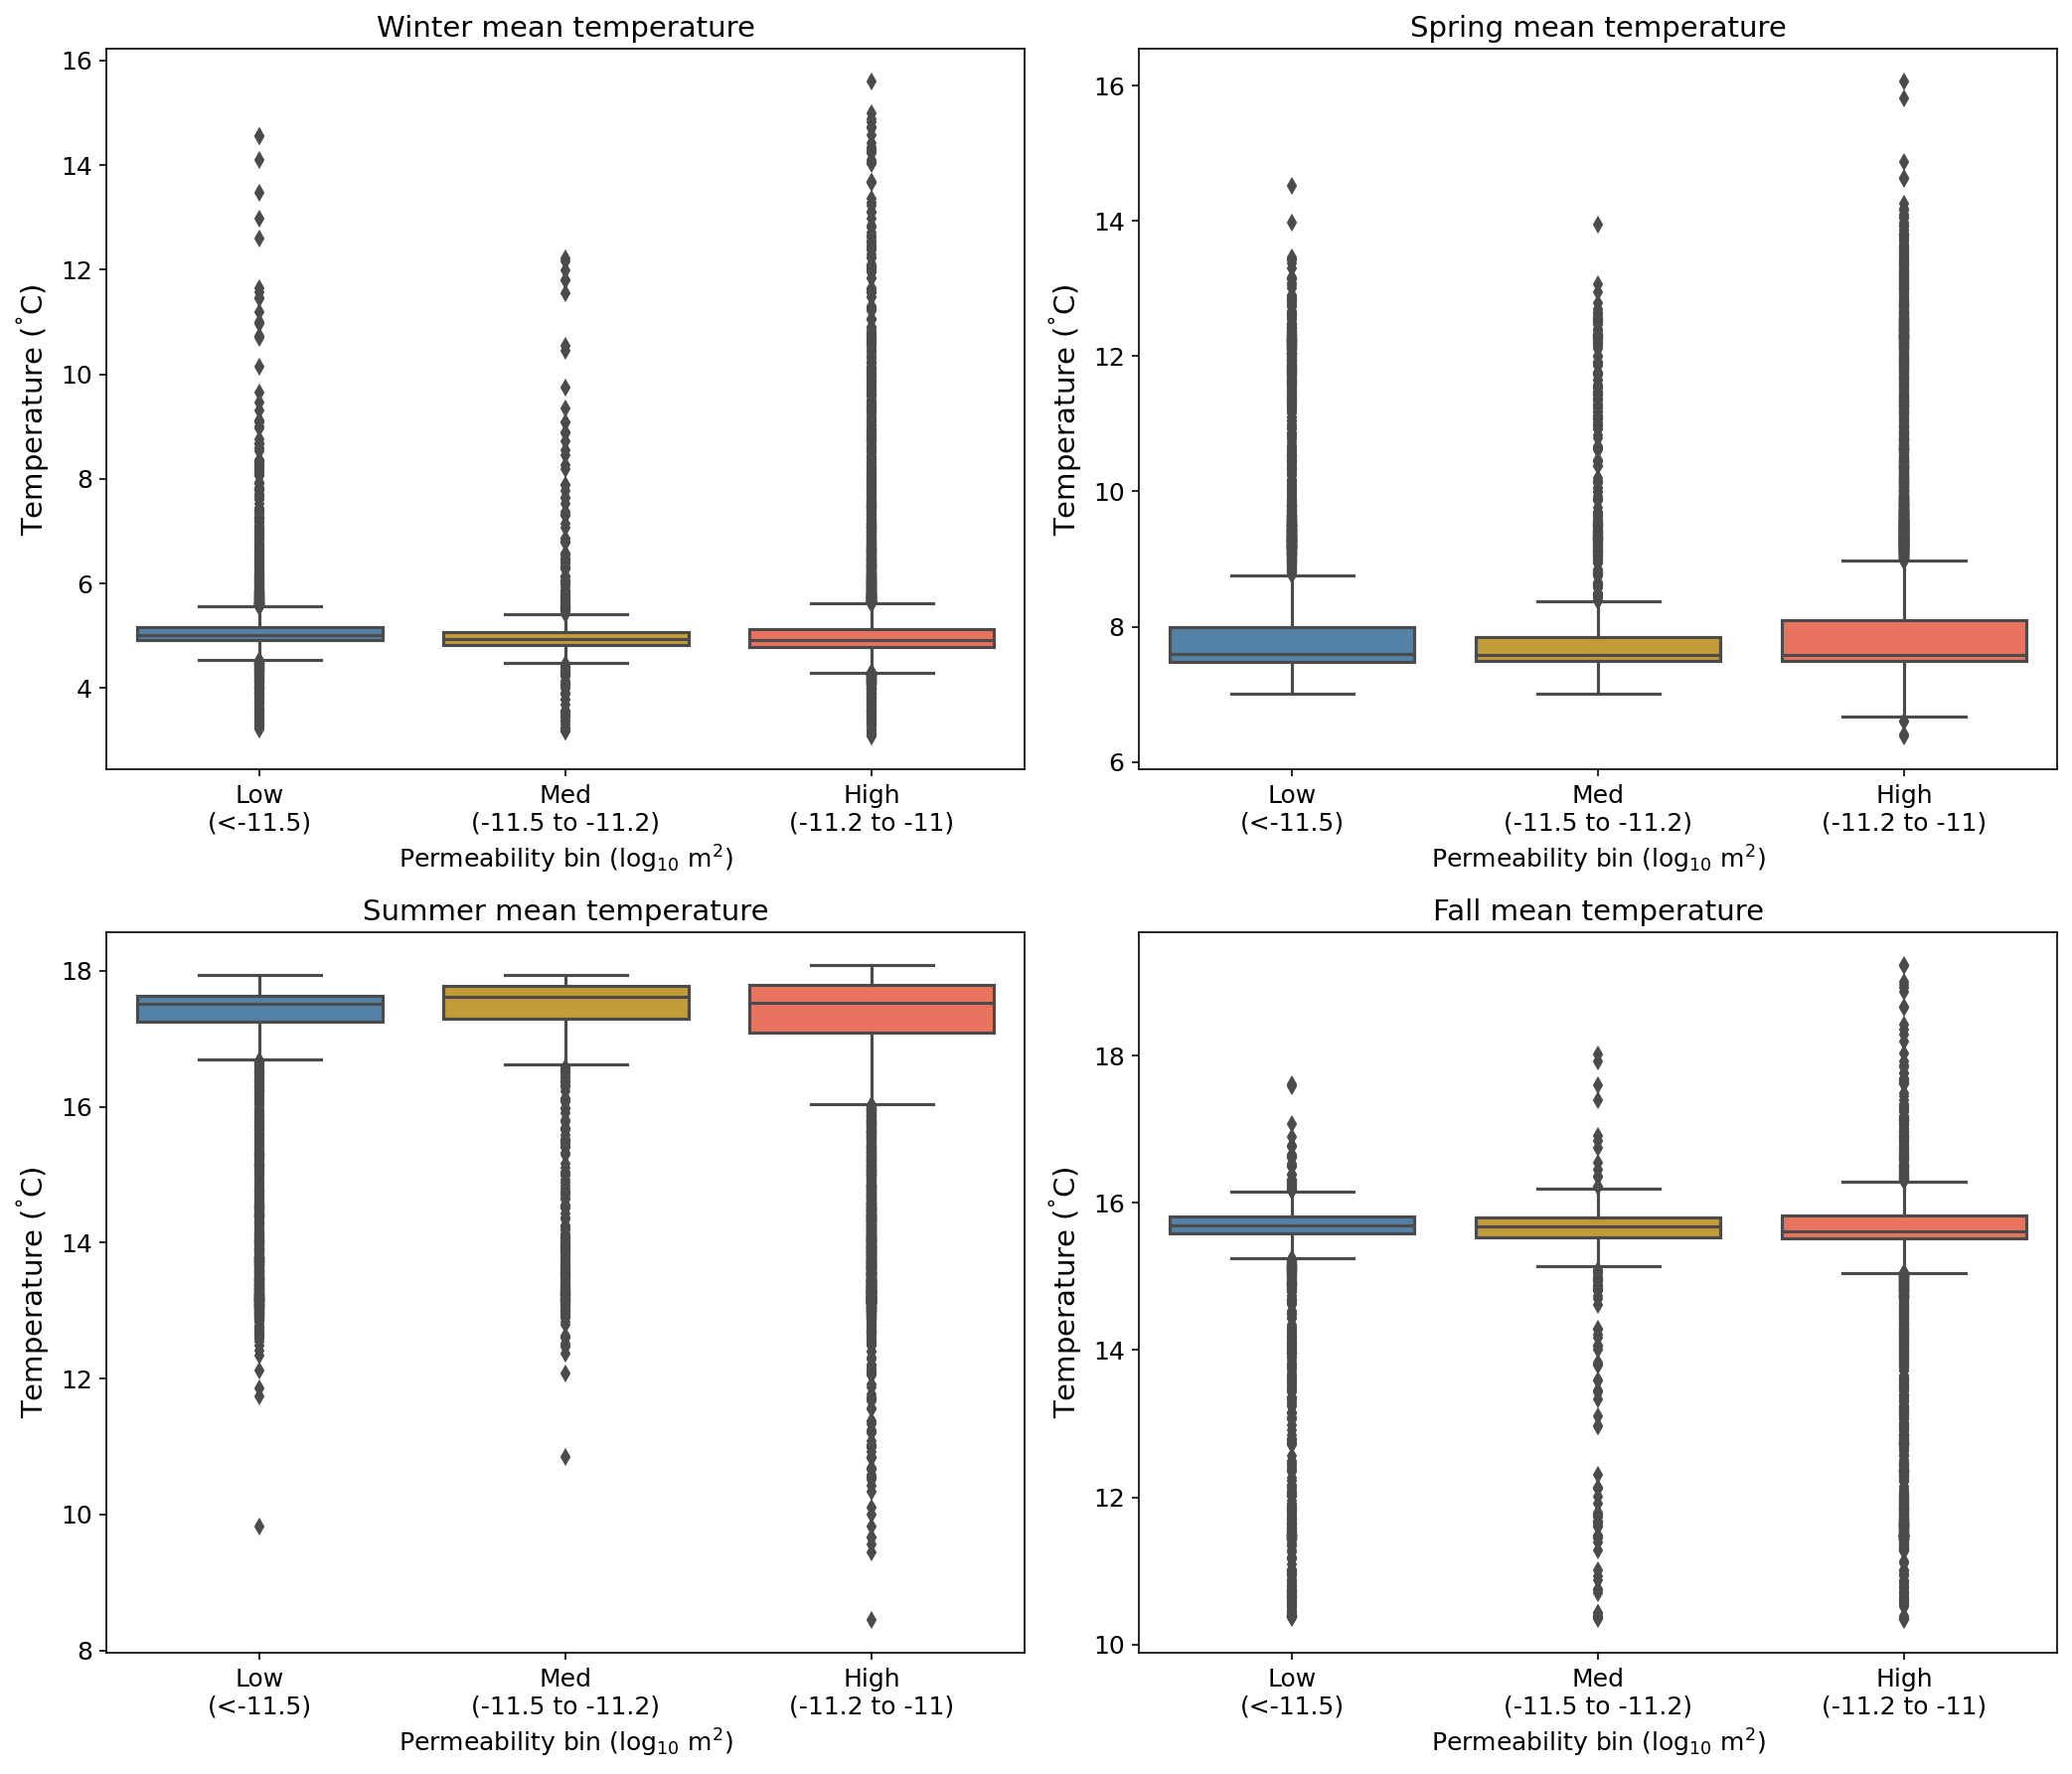

In [83]:
fig.savefig(figure_dir + f"temp_seasonal_by_perm_bin_layer{ilayer}.jpg", dpi=300)
plt.close(fig)


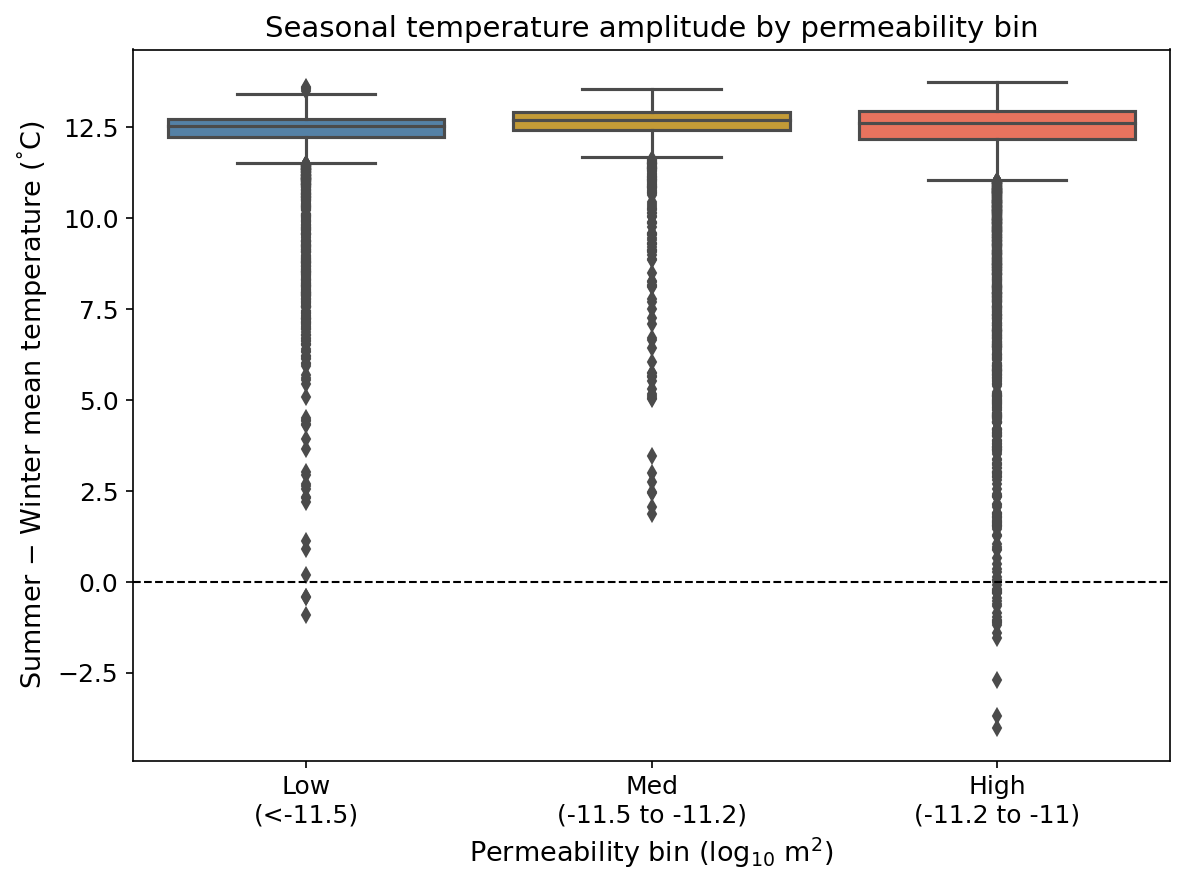

In [27]:
# ### Seasonal amplitude (summer - winter mean) by permeability bin
# High GW buffering toward 16.8°C should dampen amplitude → lower values in upwelling cells

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.boxplot(x='perm_bin', y='temp_summer_winter_amp', data=df,
            order=perm_order, palette=perm_palette, ax=ax)
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.set_xlabel('Permeability bin (log$_{10}$ m$^2$)', fontsize=13)
ax.set_ylabel('Summer − Winter mean temperature ($^\\degree$C)', fontsize=13)
ax.set_title('Seasonal temperature amplitude by permeability bin', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=12)
fig.tight_layout()

# fig.savefig(figure_dir + "temp_amplitude_by_perm_bin.jpg", dpi=300)
# plt.close(fig)

Upwelling cells (gaining_ratio > 0.5): 6783 of 18049 (37.6%)
Perm bin counts (upwelling only):
 Low\n(<-11.5)            1481
Med\n(-11.5 to -11.2)     479
High\n(-11.2 to -11)     4823
Name: perm_bin, dtype: int64


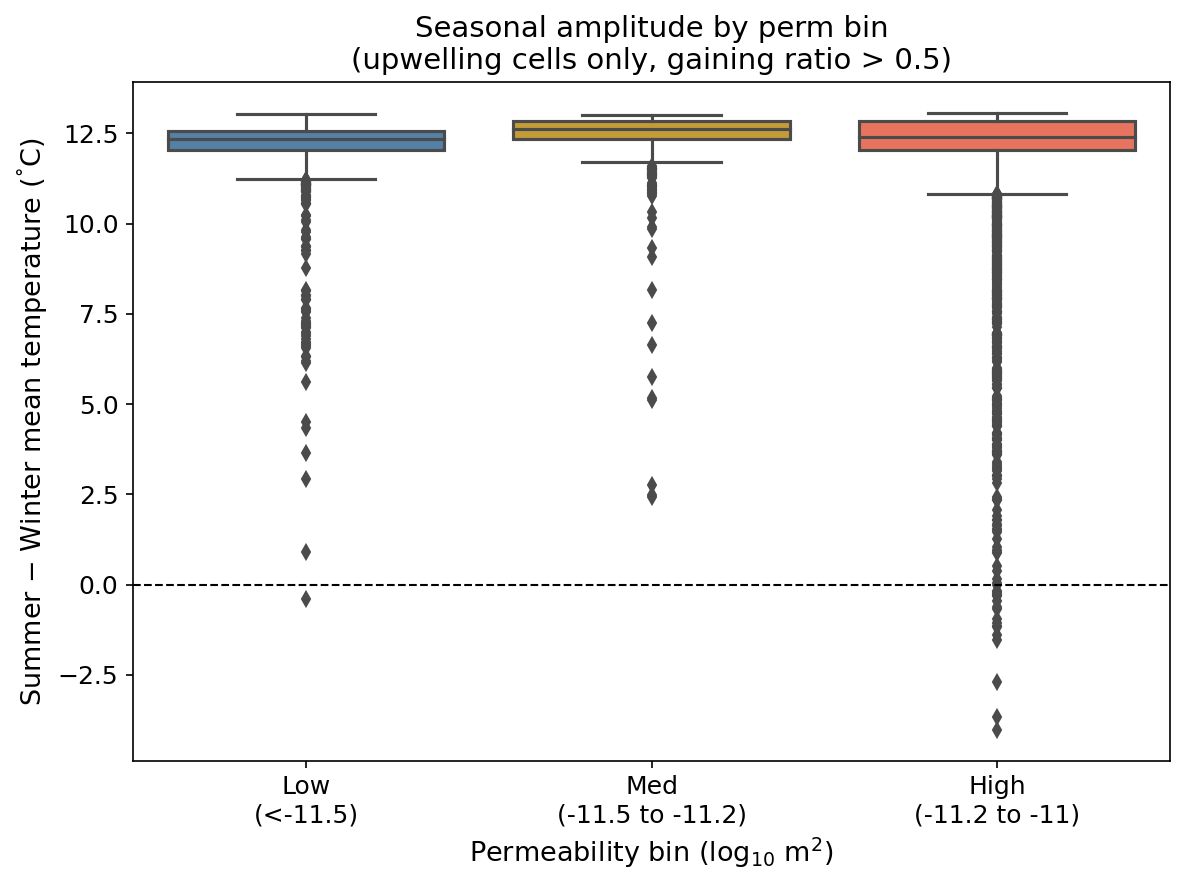

In [30]:
# ### Seasonal amplitude by permeability bin — upwelling cells only (gaining_ratio > 0.5)
# Isolates permeability effect from geomorphic positioning

df_upwelling = df[df['gaining_ratio'] > 0.5].copy()
print(f"Upwelling cells (gaining_ratio > 0.5): {len(df_upwelling)} of {len(df)} ({len(df_upwelling)/len(df)*100:.1f}%)")
print("Perm bin counts (upwelling only):\n", df_upwelling['perm_bin'].value_counts().loc[perm_order])

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.boxplot(x='perm_bin', y='temp_summer_winter_amp', data=df_upwelling,
            order=perm_order, palette=perm_palette, ax=ax)
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.set_xlabel('Permeability bin (log$_{10}$ m$^2$)', fontsize=13)
ax.set_ylabel('Summer − Winter mean temperature ($^\\degree$C)', fontsize=13)
ax.set_title('Seasonal amplitude by perm bin\n(upwelling cells only, gaining ratio > 0.5)', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=12)
fig.tight_layout()

# fig.savefig(figure_dir + "temp_amplitude_upwelling_by_perm_bin.jpg", dpi=300)
# plt.close(fig)

## Relative role of perm and HU

Permeability summary by HU (log10 scale):
              count    mean    std     min     25%    50%   75%   max
HU_name                                                              
Pool         1614.0 -11.295  0.314 -11.934 -11.585 -11.19 -11.0 -11.0
Fast glide   2312.0 -11.270  0.356 -12.010 -11.605 -11.00 -11.0 -11.0
Run          3917.0 -11.255  0.341 -12.015 -11.552 -11.00 -11.0 -11.0
Riffle      10206.0 -11.246  0.354 -12.013 -11.604 -11.00 -11.0 -11.0


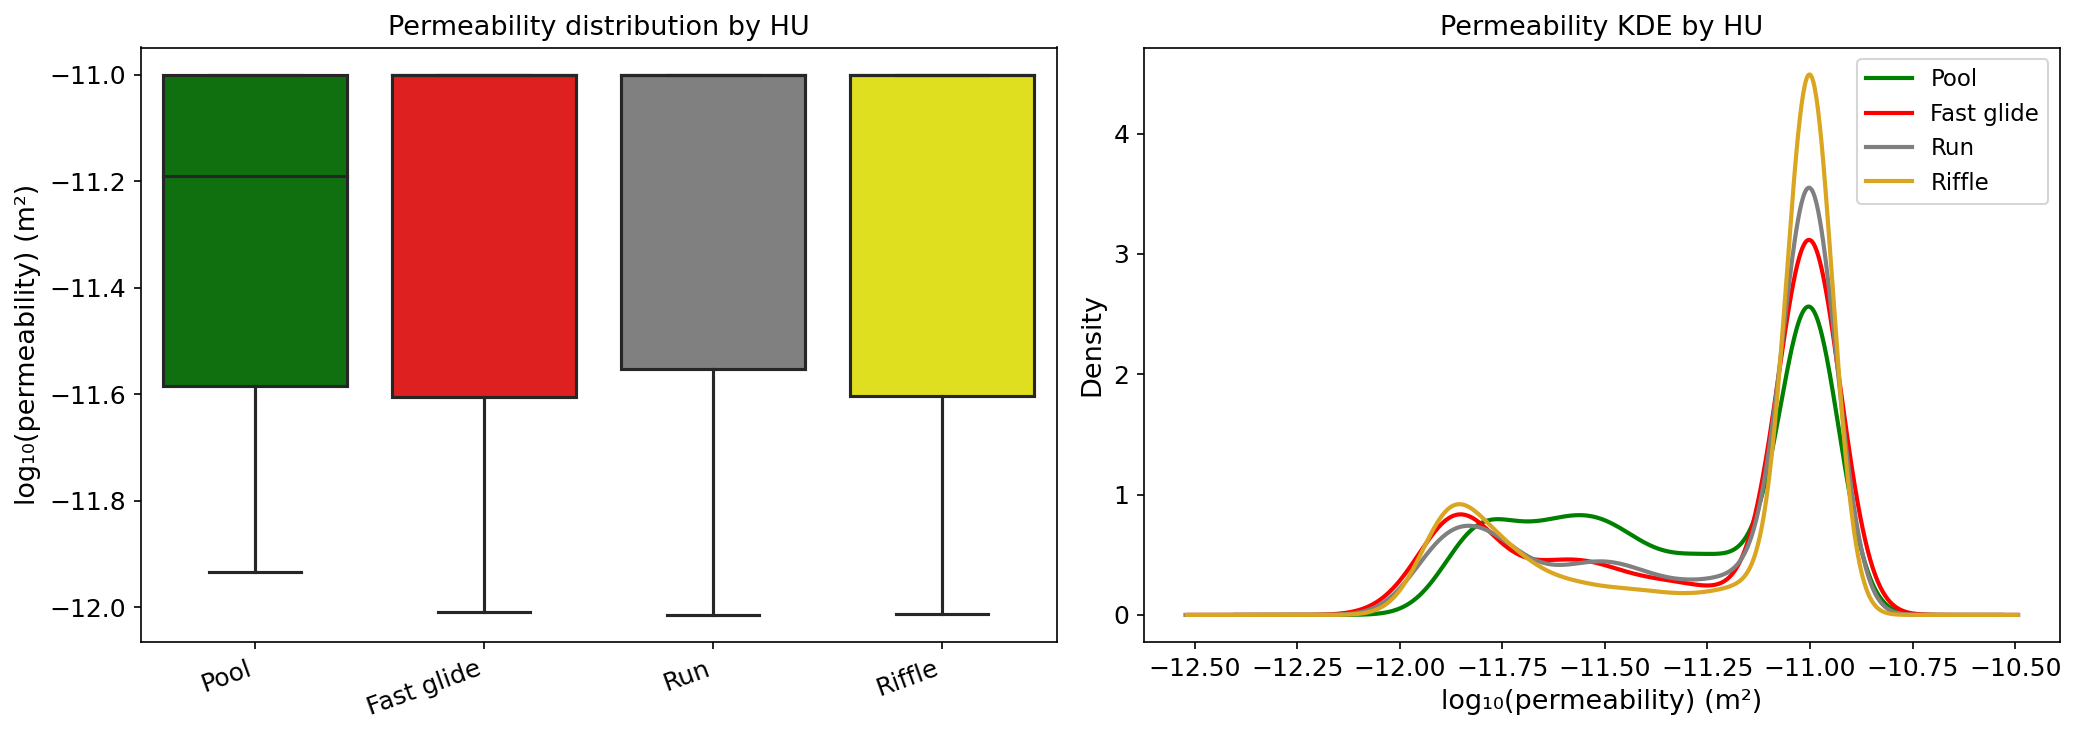

In [52]:
# --- Permeability distribution by HU ---

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: violin + embedded boxplot on log10(perm) scale
ax = axes[0]

sns.boxplot(x='HU_name', y='log_perm', data=df,
       order=HU_order, palette=HU_palette, ax=ax)
ax.set_xlabel('')
ax.set_ylabel('log\u2081\u2080(permeability) (m\u00b2)', fontsize=13)
ax.set_title('Permeability distribution by HU', fontsize=13)
ax.tick_params(axis='both', which='major', labelsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')

# Right: overlapping KDE curves on linear log-perm axis
ax = axes[1]
for hu in HU_order:
    sub = df[df['HU_name'] == hu]['log_perm'].dropna()
    if hu == 'Riffle':
        icolor = 'goldenrod'
    else:
        icolor = HU_palette[hu]
    sub.plot.kde(ax=ax, label=hu, color=icolor, linewidth=2)
ax.set_xlabel('log\u2081\u2080(permeability) (m\u00b2)', fontsize=13)
ax.set_ylabel('Density', fontsize=13)
ax.set_title('Permeability KDE by HU', fontsize=13)
ax.tick_params(axis='both', which='major', labelsize=12)
ax.legend(fontsize=11)

fig.tight_layout()

# Print summary statistics
print("Permeability summary by HU (log10 scale):")
print(df.groupby('HU_name')['log_perm'].describe().loc[HU_order].round(3))



In [48]:
fig.savefig(figure_dir + "perm_distribution_by_HU.jpg", dpi=300)
plt.close(fig)

Variance Partitioning Results:
          R2_HU  R2_perm  R2_full  unique_HU  unique_perm  shared
season                                                          
all     0.0451   0.0002   0.0455     0.0453       0.0004 -0.0002
winter  0.0131   0.0004   0.0134     0.0130       0.0002  0.0001
spring  0.1073   0.0000   0.1073     0.1073       0.0001 -0.0001
summer  0.1064   0.0000   0.1065     0.1065       0.0001 -0.0001
fall    0.0442   0.0001   0.0444     0.0443       0.0002 -0.0001


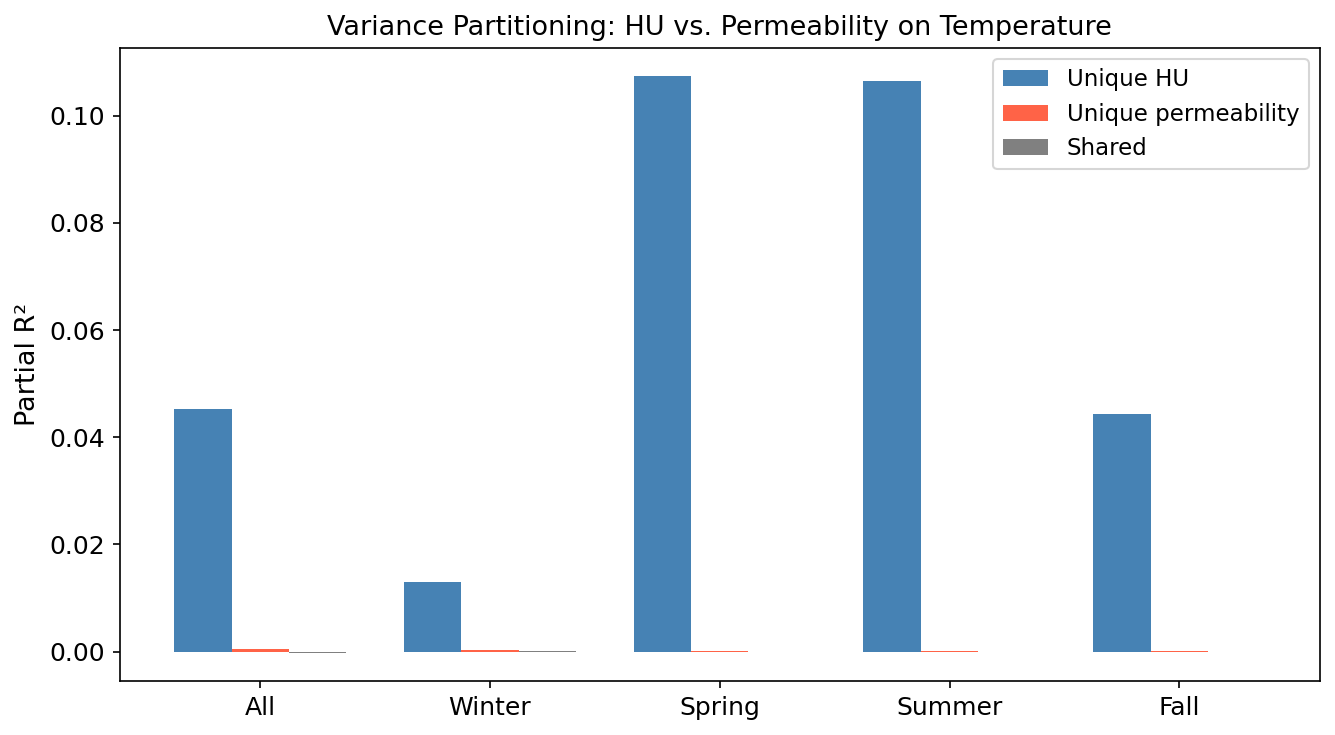

In [218]:
# --- 1. Variance Partitioning (partial R²) ---

vp_records = []
for season, tcol in temp_cols.items():
    sub = df[['HU_name', 'log_perm', tcol]].dropna()
    r2_hu   = smf.ols(f'{tcol} ~ C(HU_name)',              data=sub).fit().rsquared
    r2_perm = smf.ols(f'{tcol} ~ log_perm',                data=sub).fit().rsquared
    r2_full = smf.ols(f'{tcol} ~ C(HU_name) + log_perm',   data=sub).fit().rsquared
    vp_records.append({
        'season':      season,
        'R2_HU':       r2_hu,
        'R2_perm':     r2_perm,
        'R2_full':     r2_full,
        'unique_HU':   r2_full - r2_perm,
        'unique_perm': r2_full - r2_hu,
        'shared':      r2_hu + r2_perm - r2_full,
    })

vp_df = pd.DataFrame(vp_records).set_index('season')
print("Variance Partitioning Results:\n", vp_df.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(seasons))
w = 0.25
ax.bar(x - w, vp_df['unique_HU'],   width=w, label='Unique HU',          color='steelblue')
ax.bar(x,     vp_df['unique_perm'], width=w, label='Unique permeability', color='tomato')
ax.bar(x + w, vp_df['shared'],      width=w, label='Shared',              color='gray')
ax.set_xticks(x)
ax.set_xticklabels([s.capitalize() for s in seasons], fontsize=13)
ax.set_ylabel('Partial R²', fontsize=13)
ax.set_title('Variance Partitioning: HU vs. Permeability on Temperature', fontsize=13)
ax.legend(fontsize=11)
ax.tick_params(labelsize=12)
fig.tight_layout()

# fig.savefig(figure_dir + "variance_partitioning_HU_perm.jpg", dpi=300)
# plt.close(fig)

In [219]:
# --- 2. ANCOVA with HU × permeability interaction ---

print("\n=== ANCOVA: HU × log(permeability) interaction ===")
ancova_records = []
for season, tcol in temp_cols.items():
    sub   = df[['HU_name', 'log_perm', tcol]].dropna()
    model = smf.ols(f'{tcol} ~ C(HU_name) * log_perm', data=sub).fit()
    interaction_terms = [t for t in model.params.index
                         if 'HU_name' in t and 'log_perm' in t]
    n_sig = int((model.pvalues[interaction_terms] < 0.05).sum())
    ancova_records.append({
        'season':                 season,
        'R2':                     round(model.rsquared, 4),
        'AIC':                    round(model.aic, 1),
        'n_sig_interactions':     n_sig,
        'interaction_significant': n_sig > 0,
    })
    print(f"\n{season.upper()}: R²={model.rsquared:.4f}")
    for t in interaction_terms:
        sig = '*' if model.pvalues[t] < 0.05 else ''
        print(f"  {t}: coef={model.params[t]:.4f}, p={model.pvalues[t]:.4f} {sig}")

ancova_df = pd.DataFrame(ancova_records).set_index('season')
print("\nANCOVA Summary:\n", ancova_df)


=== ANCOVA: HU × log(permeability) interaction ===

ALL: R²=0.0459
  C(HU_name)[T.Pool]:log_perm: coef=-0.1082, p=0.0426 *
  C(HU_name)[T.Riffle]:log_perm: coef=-0.0673, p=0.0595 
  C(HU_name)[T.Run]:log_perm: coef=-0.1036, p=0.0114 *

WINTER: R²=0.0137
  C(HU_name)[T.Pool]:log_perm: coef=-0.0706, p=0.4629 
  C(HU_name)[T.Riffle]:log_perm: coef=-0.0186, p=0.7896 
  C(HU_name)[T.Run]:log_perm: coef=-0.1301, p=0.0899 

SPRING: R²=0.1076
  C(HU_name)[T.Pool]:log_perm: coef=0.1068, p=0.3688 
  C(HU_name)[T.Riffle]:log_perm: coef=0.1727, p=0.0299 *
  C(HU_name)[T.Run]:log_perm: coef=0.1424, p=0.1181 

SUMMER: R²=0.1073
  C(HU_name)[T.Pool]:log_perm: coef=-0.3992, p=0.0047 *
  C(HU_name)[T.Riffle]:log_perm: coef=-0.3717, p=0.0001 *
  C(HU_name)[T.Run]:log_perm: coef=-0.3135, p=0.0041 *

FALL: R²=0.0450
  C(HU_name)[T.Pool]:log_perm: coef=-0.1740, p=0.0943 
  C(HU_name)[T.Riffle]:log_perm: coef=-0.2309, p=0.0029 *
  C(HU_name)[T.Run]:log_perm: coef=-0.2475, p=0.0032 *

ANCOVA Summary:
      

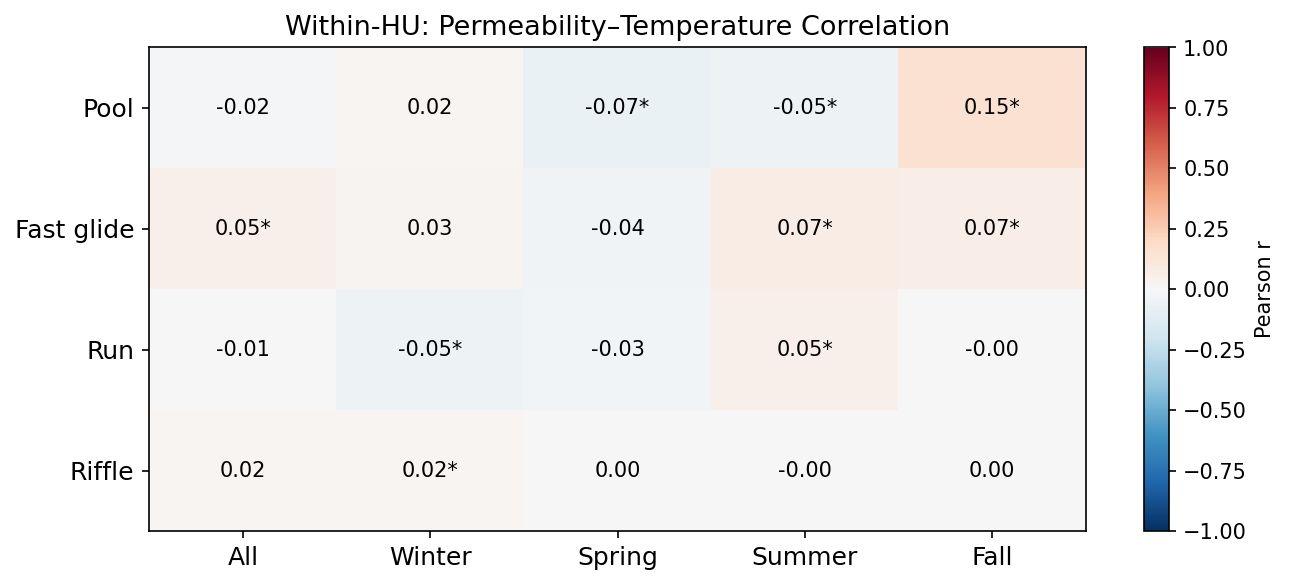

In [46]:
# --- 3. Within-HU permeability–temperature correlation ---

corr_records = []
for season, tcol in temp_cols.items():
    for hu in HU_order:
        sub = df[df['HU_name'] == hu][['log_perm', tcol]].dropna()
        if len(sub) < 10:
            continue
        r, p = pearsonr(sub['log_perm'], sub[tcol])
        corr_records.append({'season': season, 'HU': hu, 'r': r, 'p': p,
                             'significant': p < 0.05})

corr_df    = pd.DataFrame(corr_records)
# corr_pivot = corr_df.pivot(index='HU', columns='season', values='r')[seasons]
corr_pivot = corr_df.pivot(index='HU', columns='season', values='r')[seasons].loc[HU_order]


fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(corr_pivot.values, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(seasons)))
ax.set_xticklabels([s.capitalize() for s in seasons], fontsize=12)
ax.set_yticks(range(len(HU_order)))
ax.set_yticklabels(HU_order, fontsize=12)
plt.colorbar(im, ax=ax, label='Pearson r')
ax.set_title('Within-HU: Permeability–Temperature Correlation', fontsize=13)
for i, hu in enumerate(HU_order):
    for j, season in enumerate(seasons):
        row = corr_df[(corr_df['HU'] == hu) & (corr_df['season'] == season)]
        if len(row):
            r_val = row['r'].values[0]
            sig   = '*' if row['significant'].values[0] else ''
            color = 'white' if abs(r_val) > 0.5 else 'black'
            ax.text(j, i, f'{r_val:.2f}{sig}', ha='center', va='center',
                    fontsize=10, color=color)
fig.tight_layout()

# fig.savefig(figure_dir + "within_HU_perm_temp_corr.jpg", dpi=300)
# plt.close(fig)

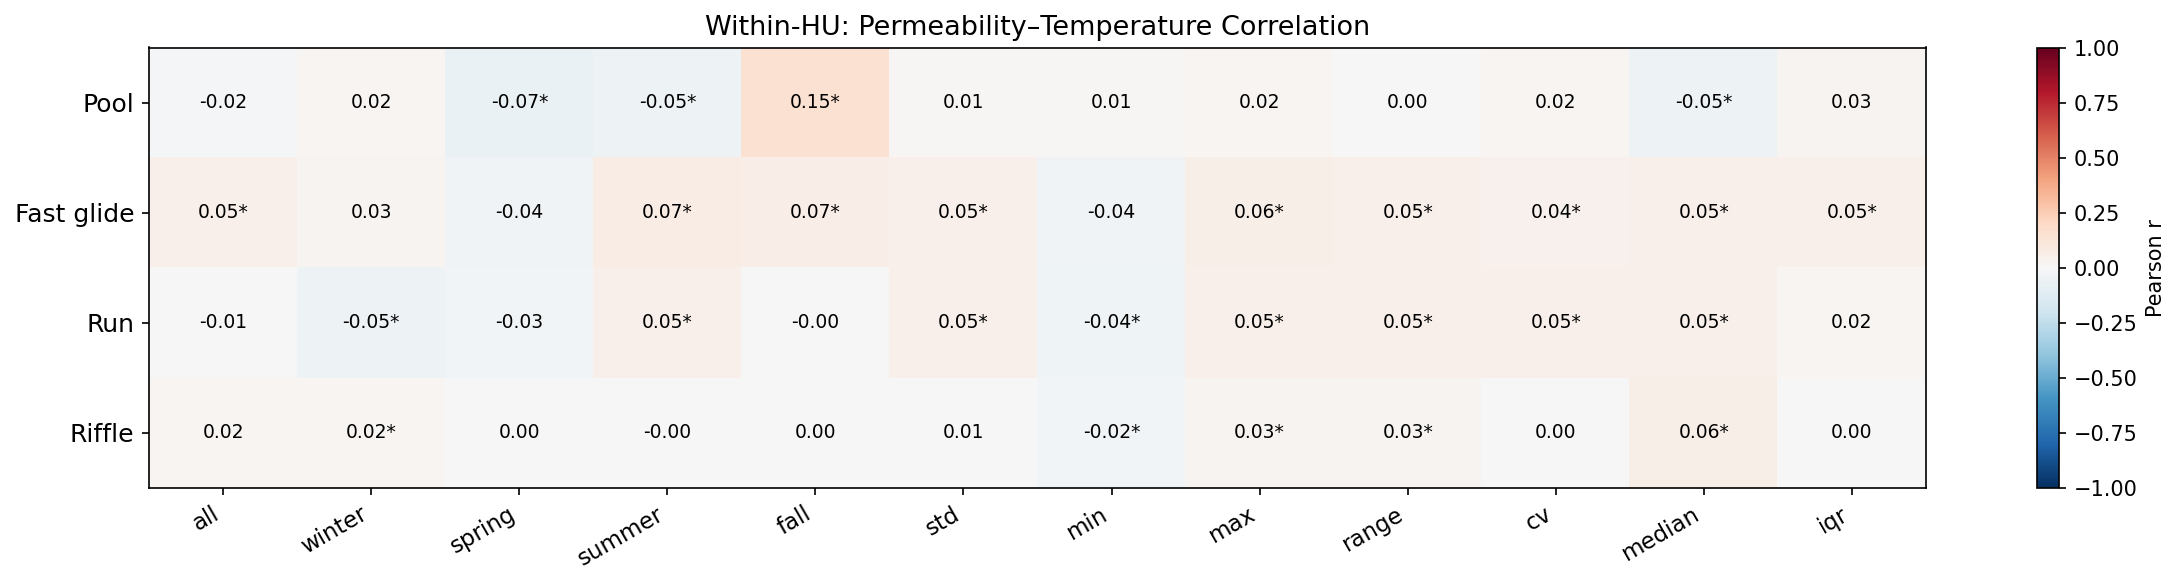

In [45]:
# --- 3. Within-HU permeability–temperature correlation ---

all_temp_cols = {
    'all':    'temp_mean',
    'winter': 'temp_mean_winter',
    'spring': 'temp_mean_spring',
    'summer': 'temp_mean_summer',
    'fall':   'temp_mean_fall',
    'std':    'temp_std',
    'min':    'temp_min',
    'max':    'temp_max',
    'range':  'temp_range',
    'cv':     'temp_cv',
    'median': 'temp_median',
    'iqr':    'temp_iqr',
}
all_metrics = list(all_temp_cols.keys())

corr_records = []
for metric, tcol in all_temp_cols.items():
    for hu in HU_order:
        sub = df[df['HU_name'] == hu][['log_perm', tcol]].dropna()
        if len(sub) < 10:
            continue
        r, p = pearsonr(sub['log_perm'], sub[tcol])
        corr_records.append({'metric': metric, 'HU': hu, 'r': r, 'p': p,
                             'significant': p < 0.05})

corr_df    = pd.DataFrame(corr_records)
# corr_pivot = corr_df.pivot(index='HU', columns='metric', values='r')[all_metrics]
corr_pivot = corr_df.pivot(index='HU', columns='metric', values='r')[all_metrics].loc[HU_order]

fig, ax = plt.subplots(figsize=(16, 4))
im = ax.imshow(corr_pivot.values, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(all_metrics)))
ax.set_xticklabels(all_metrics, fontsize=11, rotation=30, ha='right')
ax.set_yticks(range(len(HU_order)))
ax.set_yticklabels(HU_order, fontsize=12)
plt.colorbar(im, ax=ax, label='Pearson r')
ax.set_title('Within-HU: Permeability–Temperature Correlation', fontsize=13)
for i, hu in enumerate(HU_order):
    for j, metric in enumerate(all_metrics):
        row = corr_df[(corr_df['HU'] == hu) & (corr_df['metric'] == metric)]
        if len(row):
            r_val = row['r'].values[0]
            sig   = '*' if row['significant'].values[0] else ''
            color = 'white' if abs(r_val) > 0.5 else 'black'
            ax.text(j, i, f'{r_val:.2f}{sig}', ha='center', va='center',
                    fontsize=9, color=color)
fig.tight_layout()

# fig.savefig(figure_dir + "within_HU_perm_temp_corr.jpg", dpi=300)
# plt.close(fig)
